# Trabajo Práctico Aprendizaje Automático 2 - Predicción de puntuación y capitalización en texto normalizado

In [1]:
import os
import math
import copy
import gc
import re
from datasets import load_dataset
import numpy as np
import pandas as pd
import seaborn as sns
import torch
import torch.nn as nn
import torch.nn.functional as F
from torch.utils.data import Dataset, DataLoader
from torch.nn.utils.rnn import pad_sequence
import joblib
from transformers import BertModel, BertTokenizer
from sklearn.model_selection import (
    train_test_split, StratifiedGroupKFold, GroupShuffleSplit, ParameterSampler,
)
from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import f1_score
import unicodedata


from dataclasses import dataclass

In [2]:
# Seteamos la semilla para que los resultados sean reproducibles
SEED = 2026
np.random.seed(SEED)

rng = np.random.default_rng(SEED)

### Memoria

Algunos objetos ocupan mucho esta función los libera.

In [3]:
def liberar(*nombres):
    """Borra variables globales que ya no se usan y libera su memoria (si alguna no existe, no pasa nada)."""
    for nombre in nombres:
        globals().pop(nombre, None)
    gc.collect()

In [4]:
model_name = "bert-base-multilingual-cased"
tokenizer = BertTokenizer.from_pretrained(model_name)
model = BertModel.from_pretrained(model_name)
model.eval()

Loading weights:   0%|          | 0/199 [00:00<?, ?it/s]

[transformers] BertModel LOAD REPORT from: bert-base-multilingual-cased
Key                                        | Status     |  | 
-------------------------------------------+------------+--+-
cls.predictions.transform.LayerNorm.bias   | UNEXPECTED |  | 
cls.predictions.transform.LayerNorm.weight | UNEXPECTED |  | 
cls.predictions.transform.dense.bias       | UNEXPECTED |  | 
cls.predictions.bias                       | UNEXPECTED |  | 
cls.predictions.transform.dense.weight     | UNEXPECTED |  | 
cls.seq_relationship.bias                  | UNEXPECTED |  | 
cls.seq_relationship.weight                | UNEXPECTED |  | 

Notes:
- UNEXPECTED:	can be ignored when loading from different task/architecture; not ok if you expect identical arch.


BertModel(
  (embeddings): BertEmbeddings(
    (word_embeddings): Embedding(119547, 768, padding_idx=0)
    (position_embeddings): Embedding(512, 768)
    (token_type_embeddings): Embedding(2, 768)
    (LayerNorm): LayerNorm((768,), eps=1e-12, elementwise_affine=True, bias=True)
    (dropout): Dropout(p=0.1, inplace=False)
  )
  (encoder): BertEncoder(
    (layer): ModuleList(
      (0-11): 12 x BertLayer(
        (attention): BertAttention(
          (self): BertSelfAttention(
            (query): Linear(in_features=768, out_features=768, bias=True)
            (key): Linear(in_features=768, out_features=768, bias=True)
            (value): Linear(in_features=768, out_features=768, bias=True)
            (dropout): Dropout(p=0.1, inplace=False)
          )
          (output): BertSelfOutput(
            (dense): Linear(in_features=768, out_features=768, bias=True)
            (LayerNorm): LayerNorm((768,), eps=1e-12, elementwise_affine=True, bias=True)
            (dropout): Dropout(p

In [5]:
# ejemplo de tokenizar en palabras
print(tokenizer.tokenize("McDonald"))
print(tokenizer.tokenize("McRonald"))
print(tokenizer.tokenize("UBA - FCEN - ICC"))

['McDonald']
['M', '##c', '##R', '##onal', '##d']
['UB', '##A', '-', 'FC', '##EN', '-', 'ICC']


In [6]:
W = model.embeddings.word_embeddings.weight.detach().cpu().numpy()
unk_embedding = W[tokenizer.unk_token_id]  # numpy, igual que el resto de los embeddings

def embedding_palabra_promedio(palabra):
    """Promedio de los embeddings estáticos de los wordpieces de la palabra."""
    ids = tokenizer.encode(str(palabra), add_special_tokens=False)
    if not ids:
        return unk_embedding
    return W[ids].mean(axis=0)

# Lista de embeddings
def embedding_palabra_lista(palabra):
    """Lista de los embeddings estáticos de los wordpieces de la palabra."""
    ids = tokenizer.encode(str(palabra), add_special_tokens=False)
    if not ids:
        return [unk_embedding.tolist()]
    return W[ids].tolist()

In [7]:
def get_multilingual_token_embedding(token: str):
    """
    Devuelve el embedding (estático) para el token.
    """
    token_id = tokenizer.convert_tokens_to_ids(token)
    if token_id is None or token_id == tokenizer.unk_token_id:
        print(f"❌ El token '{token}' no pertenece al vocabulario de multilingualBERT.")
        return None
    embedding_vector = model.embeddings.word_embeddings.weight[token_id]

    return embedding_vector

## Datasets

Combinamos dos fuentes de datos en español. Las dos se leen en streaming desde HuggingFace (split `train` del par `en-es`) y se usa solo el lado en español:

1. **Parlamento Europeo** (`Helsinki-NLP/europarl`): texto formal, actas parlamentarias. Las oraciones vienen en el orden original del discurso. Fuente: [Europarl](https://statmt.org/europarl/)
2. **OPUS-100** (`Helsinki-NLP/opus-100`): mezcla de varios corpus de OPUS (subtítulos, documentos técnicos, etc.), con mucho lenguaje conversacional. Las oraciones vienen mezcladas, así que dos oraciones consecutivas no tienen relación entre sí. Aporta la mayoría de las preguntas.

De cada fuente se leen `N_ORACIONES_POR_FUENTE` oraciones limpias.

### Limpieza de oraciones

`limpiar_oracion` devuelve la oración limpia, o `None` si hay que descartarla. Cada oración pasa por tres pasos:
1. **Descarte directo** de casos donde el `.` no marca fin de oración (abreviaturas como `Sr.`, iniciales como `J. M.`, números como `1.500` o `2,5`), puntos suspensivos, URLs y mails.
2. **Normalización de espacios** alrededor de los signos: `"texto ?"` → `"texto?"`, `"tarde,hubo"` → `"tarde, hubo"`, `"bien,¿no?"` → `"bien, ¿no?"`.
3. **Validación**: al menos `MIN_PALABRAS_ORACION` palabras (no hay máximo); cada palabra es un `¿` opcional, letras/dígitos/`'`/`-` y a lo sumo un `.`, `,` o `?` al final; empieza en mayúscula; termina en `.` o `?`; los `¿?` están balanceados y sin anidar; al menos la mitad de los caracteres son letras.

Los signos que no predecimos **no se convierten**: una oración con `!`, `¡`, `;`, `:`, comillas o paréntesis no pasa la validación y se descarta. Los guiones sí se conservan, también sueltos (`"- Gracias."`): forman parte de la palabra.

In [8]:
# Parámetros del dataset
N_ORACIONES_POR_FUENTE = 100000        # Oraciones limpias a leer de cada fuente
MIN_PALABRAS_ORACION = 1             # Descartamos oraciones vacías
MAX_ORACIONES_POR_DOCUMENTO = 20     # Oraciones consecutivas que forman un "documento"

MIN_PALABRAS_INSTANCIA = 10          # Largo mínimo de cada recorte
MAX_PALABRAS_INSTANCIA = 50          # Largo máximo de cada recorte
PROB_ORACIONES_SUELTAS = 0.15        # Proporción de documentos que se usan como oraciones sueltas, esto está porque de otra manera existen pocas oraciones que terminen con puntuación final no nula.

PROPORCION_TEST = 0.2                # Proporción de documentos para control (el resto es desarrollo)

RUTA_DATOS = "datos"                 # Carpeta donde se guarda el dataset ya armado
RUTA_MODELOS = "modelos"             # Carpeta donde se guardan los modelos entrenados
RUTA_HISTORIALES = "historial_rnn"   # Carpeta donde se guarda el historial de entrenamiento de cada red

In [9]:
ABREVIATURAS = {
    "sr.", "sra.", "sres.", "sras.", "srta.", "dr.", "dra.", "ud.", "uds.",
    "art.", "arts.", "núm.", "nº.", "pág.", "págs.", "vol.", "cap.",
    "etc.", "ej.", "p.ej.", "aprox.", "ee.uu.", "a.c.", "d.c.",
}


# Decidir si descartar de entrada o si se puede limpiar de alguna forma
def descartar_de_entrada(texto):
    """Casos que no vale la pena intentar limpiar."""
    if "..." in texto or "…" in texto:
        return True
    if "http" in texto or "www" in texto or "@" in texto:
        return True
    # Números con punto o coma (ej: "1.500", "2,5"): el "." no sería fin de oración
    if re.search(r"\d[.,]\d", texto):
        return True
    # Abreviaturas (ej: "Sr. López"): el "." no sería fin de oración
    if any(palabra.lower() in ABREVIATURAS for palabra in texto.split()):
        return True
    # Iniciales (ej: "J. M. Barroso")
    if re.search(r"\b[A-ZÁÉÍÓÚÑ]\.\s", texto):
        return True
    return False


def normalizar_espacios_puntuacion(texto):
    # Quita espacios antes de '?', '.' o ',' (ej: "texto ?" -> "texto?")
    texto = re.sub(r"\s+([?.,])", r"\1", texto)
    # Agrega un espacio después de '?', '.' o ',' si quedaron pegados (ej: "tarde,hubo")
    texto = re.sub(r"([?.,])(?=\w)", r"\1 ", texto)
    # Quita espacios después de '¿' y agrega uno antes si quedó pegado (ej: "bien,¿no?")
    texto = re.sub(r"¿\s+", "¿", texto)
    texto = re.sub(r"(?<=\S)¿", " ¿", texto)
    # Elimina espacios múltiples
    texto = re.sub(r"\s+", " ", texto).strip()
    return texto


def es_oracion_valida(texto):
    palabras = texto.split()
    if not (MIN_PALABRAS_ORACION <= len(palabras)):
        return False

    # Cada palabra: un '¿' opcional al inicio, la palabra, y a lo sumo un signo al final
    if any(not re.fullmatch(r"¿?[\w'-]+[.,?]?", palabra) for palabra in palabras):
        return False

    # Tiene que parecer una oración completa: empieza en mayúscula y termina en . o ?
    primera_letra = next((c for c in texto if c.isalpha()), "")
    if not primera_letra.isupper():
        return False
    if not (texto.endswith(".") or texto.endswith("?")):
        return False

    # Los '¿' y '?' tienen que estar balanceados y sin anidar
    balance = 0
    for char in texto:
        if char == "¿":
            balance += 1
        elif char == "?":
            balance -= 1
        if balance < 0 or balance > 1:
            return False
    if balance != 0:
        return False

    n_letras = sum(1 for c in texto if c.isalpha())
    if n_letras < len(texto) * 0.5:
        return False

    return True


def limpiar_oracion(texto):
    """Devuelve la oración limpia, o None si hay que descartarla."""
    texto = texto.strip()
    if descartar_de_entrada(texto):
        return None
    texto = normalizar_espacios_puntuacion(texto)
    if not es_oracion_valida(texto):
        return None
    return texto

In [10]:
ejemplos = [
    "Fueron los asbestos aquí. ¡Eso es lo que ocurrió!",
    "Y prefiero mudarme, ¿Entiendes?",
    "- Gracias.",
    "Sería -me parece a mí- lo mínimo, al alba del tercer milenio.",
    "Esta tarde,hubo conciertos en las ciudades ocupadas.",
    "Éstas ofrecen tres garantías: ningún petrolero podrá hacer escala; todas las partes deberán responder.",
    "Vamos a McDonald's con el Sr. Pérez.",
    "en el apartado 2, el párrafo primero se sustituye por el texto siguiente:",
    "Perdón, he tenido una burbuja de gas extraño un momentito",
]

for ejemplo in ejemplos:
    print(f"{ejemplo!r}\n  -> {limpiar_oracion(ejemplo)!r}")

'Fueron los asbestos aquí. ¡Eso es lo que ocurrió!'
  -> None
'Y prefiero mudarme, ¿Entiendes?'
  -> 'Y prefiero mudarme, ¿Entiendes?'
'- Gracias.'
  -> '- Gracias.'
'Sería -me parece a mí- lo mínimo, al alba del tercer milenio.'
  -> 'Sería -me parece a mí- lo mínimo, al alba del tercer milenio.'
'Esta tarde,hubo conciertos en las ciudades ocupadas.'
  -> 'Esta tarde, hubo conciertos en las ciudades ocupadas.'
'Éstas ofrecen tres garantías: ningún petrolero podrá hacer escala; todas las partes deberán responder.'
  -> None
"Vamos a McDonald's con el Sr. Pérez."
  -> None
'en el apartado 2, el párrafo primero se sustituye por el texto siguiente:'
  -> None
'Perdón, he tenido una burbuja de gas extraño un momentito'
  -> None


In [11]:
def leer_documentos(nombre_dataset):
    """
    Lee el dataset en streaming y lo agrupa en documentos: listas de oraciones
    limpias que aparecen de forma consecutiva en la fuente.

    Si una oración se descarta, se corta el documento actual para no unir
    oraciones que en el original tenían texto en el medio.
    """
    stream = load_dataset(nombre_dataset, "en-es", split="train", streaming=True)

    documentos = []
    documento_actual = []
    n_oraciones = 0

    for ejemplo in stream:
        oracion = limpiar_oracion(ejemplo["translation"]["es"])

        if oracion is None:
            if documento_actual:
                documentos.append(documento_actual)
                documento_actual = []
            continue

        documento_actual.append(oracion)
        n_oraciones += 1

        if len(documento_actual) == MAX_ORACIONES_POR_DOCUMENTO:
            documentos.append(documento_actual)
            documento_actual = []

        if n_oraciones >= N_ORACIONES_POR_FUENTE:
            break

    if documento_actual:
        documentos.append(documento_actual)

    return documentos

### Armado de instancias

Ambos datasets están segmentados por oración. Si entrenáramos con oraciones completas, los modelos aprenderían un **sesgo posicional**: que la primera palabra siempre va en mayúscula y que `.` y `?` aparecen solo en la última palabra. Pero el enunciado aclara que cada instancia de evaluación puede contener *parte* de una o varias oraciones. Por eso la mayoría de las instancias son recortes que cortan oraciones, y una parte menor son oraciones completas, para que los modelos vean los dos casos.

Para evitarlo:
1. **Documentos**: agrupamos hasta `MAX_ORACIONES_POR_DOCUMENTO` oraciones consecutivas válidas. Si una oración se descarta, el documento se corta, para no unir oraciones que en el original tenían texto en el medio. En *Europarl* esto reconstruye fragmentos reales de un mismo discurso. En *OPUS-100* las oraciones no tienen relación entre sí, pero como los modelos usan sobre todo contexto local, el cambio de tema entre oraciones no debería afectar mucho. Cada documento guarda `primera_oracion`: en qué número de oración (dentro de su fuente) empieza. Los Random Forest la usan para quedarse solo con las primeras oraciones de cada fuente.
2. **Divisiones por documento**: cada instancia guarda su `documento_id` y ninguna instancia mezcla documentos. Todas las divisiones (desarrollo / control, train / validación y los folds de la búsqueda de hiperparámetros) se hacen por documento, así no hay fragmentos de un mismo texto en dos conjuntos.
3. **Recortes**: cada documento se sortea por separado.
   - Con probabilidad `PROB_ORACIONES_SUELTAS` (15%), cada oración del documento es una instancia (oraciones sueltas). Estas instancias no respetan `MIN_PALABRAS_INSTANCIA`: una oración de una palabra (`"Gracias."`) es una instancia.
   - Si no, juntamos las palabras de todas sus oraciones y las cortamos en tramos consecutivos de largo aleatorio (entre `MIN_PALABRAS_INSTANCIA` y `MAX_PALABRAS_INSTANCIA` palabras). Los tramos pueden empezar y terminar a mitad de oración. El último tramo de cada documento es lo que sobra, así que puede quedar más corto que `MIN_PALABRAS_INSTANCIA`.
4. **Fuentes separadas**: nunca se mezclan oraciones de *Europarl* y *OPUS-100* en una misma instancia.

### Etiquetas (a nivel palabra)

`df_palabras` tiene una fila por palabra, con las etiquetas codificadas como enteros:
- `punt_inicial`: 0 (sin signo), 1 (`¿`)
- `punt_final`: 0 (sin signo), 1 (`.`), 2 (`,`), 3 (`?`)
- `capitalizacion`: 0 (minúsculas), 1 (primera letra), 2 (mixta, ej: `iPhone`), 3 (todo mayúsculas, más de una letra)

`palabra` es la entrada de los modelos (minúsculas y sin signos). `palabra_original` conserva las mayúsculas: las redes la usan para saber cómo se escribe cada token (ver *Redes neuronales*).

Los Random Forest predicen por palabra; las redes, por token de BERT. La entrega es siempre **por token**: para pasar de un formato al otro están las funciones de *Formato de entrega* en *Herramientas comunes*.

In [12]:
def recortar_instancias(documento, rng):
    """
    Convierte un documento en instancias (listas de palabras con puntuación y mayúsculas).

    - Con probabilidad PROB_ORACIONES_SUELTAS, cada oración es una instancia.
    - Si no, se juntan todas las oraciones y se recortan tramos de largo aleatorio,
    que pueden empezar y terminar a mitad de oración.
    """
    if rng.random() < PROB_ORACIONES_SUELTAS:
    # Asumimos que cada elemento de 'documento' es una oración en string o ya una lista
        return [oracion.split() if isinstance(oracion, str) else oracion for oracion in documento]


    # Si 'documento' es una lista de oraciones (strings), primero las aplanamos correctamente a nivel de palabras
    palabras = []
    for oracion in documento:
        if isinstance(oracion, str):
            palabras.extend(oracion.split())
        else:
            palabras.extend(oracion)

    instancias = []
    inicio = 0
    while inicio < len(palabras):
        largo = rng.integers(MIN_PALABRAS_INSTANCIA, MAX_PALABRAS_INSTANCIA + 1)
        instancia = palabras[inicio:inicio + largo]

        # El último tramo es lo que sobra y puede quedar más corto que MIN_PALABRAS_INSTANCIA
        if len(instancia) >= MIN_PALABRAS_ORACION:
            instancias.append(instancia)
        inicio += largo

    return instancias



def capitalizacion(palabra):
    """0: minúsculas, 1: primera mayúscula, 2: mixta (ej: iPhone), 3: todo mayúsculas."""
    letras = [c for c in palabra if c.isalpha()]
    if not any(c.isupper() for c in letras):
        return 0
    if len(letras) > 1 and all(c.isupper() for c in letras):
        return 3
    if letras[0].isupper() and not any(c.isupper() for c in letras[1:]):
        return 1
    return 2


def etiquetar_palabra(palabra_cruda):
    """
    Recibe una palabra tal como aparece en el texto (ej: "¿Cuándo", "UBA?")
    y devuelve la palabra normalizada junto con sus etiquetas.
    """
    def char_a_int(char):
        if char == ".":
            return 1
        elif char == ",":
            return 2
        else:
            return 3
    # Puntuación inicial → 0: nada, 1: '¿'
    # Puntuación final → 0: nada, 1: '.', 2: ',', 3: '?'
    punt_inicial = 1 if palabra_cruda.startswith("¿") else 0
    ultimo_char = palabra_cruda[-1]
    punt_final = char_a_int(ultimo_char) if ultimo_char in ".,?" else 0
    palabra_original = palabra_cruda.strip("¿?.,")

    return {
        "palabra": palabra_original.lower(),
        "palabra_original": palabra_original,
        "punt_inicial": punt_inicial,
        "punt_final": punt_final,
        "capitalizacion": capitalizacion(palabra_original),
    }


def construir_dataset(documentos_por_fuente, rng):
    """
    Devuelve dos DataFrames:
    - df_instancias: una fila por instancia, con el texto original y el documento del que salió.
    - df_palabras: una fila por palabra, con las etiquetas (formato del TP, a nivel palabra).
    Cada fila guarda también primera_oracion: en qué número de oración (dentro de su fuente)
    empieza su documento.
    """
    filas_instancias = []
    filas_palabras = []
    instancia_id = 0
    documento_id = 0

    for fuente, documentos in documentos_por_fuente.items():
        oraciones_leidas = 0  # oraciones de esta fuente antes del documento actual
        for documento in documentos:
            for instancia in recortar_instancias(documento, rng):
                filas_instancias.append({
                    "instancia_id": instancia_id,
                    "documento_id": documento_id,
                    "fuente": fuente,
                    "primera_oracion": oraciones_leidas,
                    "texto": " ".join(instancia),
                })
                for posicion, palabra_cruda in enumerate(instancia):
                    fila = {"instancia_id": instancia_id, "posicion": posicion}
                    fila.update(etiquetar_palabra(palabra_cruda))
                    filas_palabras.append(fila)
                instancia_id += 1
            documento_id += 1
            oraciones_leidas += len(documento)

    df_instancias = pd.DataFrame(filas_instancias)
    df_palabras = pd.DataFrame(filas_palabras)
    df_palabras = df_palabras.merge(df_instancias[["instancia_id", "documento_id", "fuente", "primera_oracion"]], on="instancia_id")
    return df_instancias, df_palabras

In [13]:
ruta_instancias = os.path.join(RUTA_DATOS, "instancias.csv")
ruta_palabras = os.path.join(RUTA_DATOS, "palabras.csv")

# ACÁ SE DEFINEN df_instancias y df_palabras, ya sea cargándolos desde disco o armándolos desde cero
if os.path.exists(ruta_instancias) and os.path.exists(ruta_palabras) and False: # Si queres cargar desde disco, cambia False por True
    # keep_default_na=False para que la "sin puntuación" ("") no se lea como NaN
    df_instancias = pd.read_csv(ruta_instancias, keep_default_na=False)
    df_palabras = pd.read_csv(ruta_palabras, keep_default_na=False)
    print("Dataset cargado desde disco")
else:
    documentos_por_fuente = {
        "europarl": leer_documentos("Helsinki-NLP/europarl"),
        "opus100": leer_documentos("Helsinki-NLP/opus-100"),
    }
    for fuente, documentos in documentos_por_fuente.items():
        print(f"{fuente}: {len(documentos)} documentos")

    df_instancias, df_palabras = construir_dataset(documentos_por_fuente, rng)

    os.makedirs(RUTA_DATOS, exist_ok=True)
    df_instancias.to_csv(ruta_instancias, index=False)
    df_palabras.to_csv(ruta_palabras, index=False)
    print("Dataset armado y guardado en", RUTA_DATOS)

print(f"Instancias: {len(df_instancias)} | Palabras: {len(df_palabras)}")

europarl: 17050 documentos
opus100: 31138 documentos
Dataset armado y guardado en datos
Instancias: 153725 | Palabras: 3479183


### Chequeo de clases

- **Distribución de clases por fuente:** cuántas palabras hay de cada clase en cada tarea, en cantidad y en porcentaje. Muestra el desbalance (`¿`, `?` y la capitalización Mixta son muy raras) y que OPUS-100 aporta la mayoría de las preguntas.
- **Sesgo posicional:** si los recortes funcionan, `.` y `?` tienen que aparecer también en el medio de las instancias (no solo al final), y muchas instancias tienen que terminar a mitad de oración y empezar en minúscula. Las oraciones sueltas suben la proporción de signos en la última palabra (con 15%, alrededor del 36% de los `.` quedan al final; sin ellas sería un 25%).

In [14]:
# Distribución de clases a nivel palabra, por fuente
for columna in ["punt_inicial", "punt_final", "capitalizacion"]:
    tabla = pd.crosstab(df_palabras[columna], df_palabras["fuente"], margins=True)
    porcentajes = pd.crosstab(df_palabras[columna], df_palabras["fuente"], normalize="columns").round(4) * 100
    print(f"--- {columna} (cantidad de palabras) ---")
    print(tabla)
    print(f"--- {columna} (% por fuente) ---")
    print(porcentajes, "\n")

--- punt_inicial (cantidad de palabras) ---
fuente        europarl  opus100      All
punt_inicial                            
0              2510397   948079  3458476
1                 3242    17465    20707
All            2513639   965544  3479183
--- punt_inicial (% por fuente) ---
fuente        europarl  opus100
punt_inicial                   
0                99.87    98.19
1                 0.13     1.81 

--- punt_final (cantidad de palabras) ---
fuente      europarl  opus100      All
punt_final                            
0            2269898   811694  3081592
1              99221    87565   186786
2             141278    48820   190098
3               3242    17465    20707
All          2513639   965544  3479183
--- punt_final (% por fuente) ---
fuente      europarl  opus100
punt_final                   
0              90.30    84.07
1               3.95     9.07
2               5.62     5.06
3               0.13     1.81 

--- capitalizacion (cantidad de palabras) ---
fuente  

In [15]:
# Chequeo del sesgo posicional: ¿los signos de cierre siguen apareciendo solo al final?
# punt_final está codificado: 1 = '.', 3 = '?'
ultima_posicion = df_palabras.groupby("instancia_id")["posicion"].transform("max")
es_ultima = df_palabras["posicion"] == ultima_posicion
es_primera = df_palabras["posicion"] == 0

for codigo, signo in [(1, "."), (3, "?")]:
    con_signo = df_palabras["punt_final"] == codigo
    intermedios = (con_signo & ~es_ultima).sum()
    print(f"'{signo}': {con_signo.sum()} en total, {intermedios} en el medio de una instancia "
          f"({intermedios / con_signo.sum():.1%})")

termina_cortada = es_ultima & ~df_palabras["punt_final"].isin([1, 3])
empieza_minuscula = es_primera & (df_palabras["capitalizacion"] == 0)
print(f"Instancias que terminan a mitad de oración: {termina_cortada.sum() / len(df_instancias):.1%}")
print(f"Instancias que empiezan en minúscula: {empieza_minuscula.sum() / len(df_instancias):.1%}")

'.': 186786 en total, 120439 en el medio de una instancia (64.5%)
'?': 20707 en total, 12473 en el medio de una instancia (60.2%)
Instancias que terminan a mitad de oración: 51.5%
Instancias que empiezan en minúscula: 51.6%


In [16]:
# Fin de la sección: liberamos lo que ya no se usa más adelante
# model (BERT completo) tampoco: los embeddings estáticos quedaron en W. Si necesitás
# get_multilingual_token_embedding, volvé a correr la celda que carga BERT.
liberar(
    "model", "documentos_por_fuente", "ejemplos", "ejemplo", "ruta_instancias", "ruta_palabras",
    "tabla", "porcentajes", "columna", "ultima_posicion", "es_ultima", "es_primera",
    "con_signo", "intermedios", "codigo", "signo", "termina_cortada", "empieza_minuscula",
)

## Herramientas comunes

- **Parámetros**: las tareas (`TAREAS`, `CLASES`) y cómo se valida (`N_FOLDS`, `PROPORCION_VALIDACION`, `COLUMNA_GRUPO`).
- **Desarrollo / control**: los datos se dividen por documento, estratificando por fuente. Con desarrollo se hace todo (búsqueda de hiperparámetros, entrenamiento, validación). Control se usa **solo al final**, cuando ya no se usan más los datos de desarrollo.
- **Reconstrucción del texto** a partir de las etiquetas, para ver las predicciones.
- **Un modelo por tarea**: `entrenar` y `validar` (F1 por clase y macro).
- **Umbrales de decisión**: `ajustar_pesos` corre el umbral de cada clase para maximizar el F1 macro; lo usan `validar` (RF) y `validar_nn` (redes).
- **Validación y búsqueda de hiperparámetros**: `separar_validacion` (desarrollo → train / validación) y `busqueda_aleatoria`.
- **Formato de entrega**: de tokens a palabras y de vuelta, y `predecir_por_token` para los modelos que predicen por palabra (Random Forest).

### Parámetros

In [17]:
TAREAS = ["punt_final", "capitalizacion", "punt_inicial"]

# Clases de cada tarea, en el orden de sus códigos (punt_final: 0 = sin signo, 1 = ".", 2 = ",", 3 = "?")
CLASES = {
    "punt_inicial": ["", "¿"],
    "punt_final": ["", ".", ",", "?"],
    "capitalizacion": [0, 1, 2, 3],
}

# Parámetros de la validación
N_FOLDS = 3                  # 1: una sola partición train / validación. >1: k-fold
PROPORCION_VALIDACION = 0.2  # Solo se usa si N_FOLDS == 1
COLUMNA_GRUPO = "documento_id"  # Lo que nunca se separa entre train y validación: "documento_id" o "instancia_id"

# Columnas de df_palabras que no son atributos (identificadores y etiquetas)
COLUMNAS_NO_ATRIBUTOS = [
    "instancia_id", "documento_id", "fuente", "primera_oracion", "split", "palabra", "palabra_original",
    "punt_inicial", "punt_final", "capitalizacion",
]

# Función auxiliar para obtener las columnas de atributos a partir de un DataFrame
def columnas_de_atributos(df: pd.DataFrame) -> list:
    return [c for c in df.columns if c not in COLUMNAS_NO_ATRIBUTOS]

### Desarrollo y control

Se sortean **documentos** (no palabras), estratificando por fuente: todas las palabras de un documento quedan del mismo lado. Después de esta celda, `df_palabras` y `df_instancias` son solo los de desarrollo; los de control quedan en `df_test_palabras` y `df_test_instancias`.

In [18]:
# Dividir en conjunto de desarrollo y control POR DOCUMENTO (control se usa solo al final,
# cuando ya no se usan más los datos de desarrollo): todas las palabras de un mismo
# documento quedan del mismo lado. Si se separa a nivel palabra, palabras vecinas de la misma
# instancia caen en train y en test, y la evaluación da mejor de lo que es.
fuente_por_documento = df_instancias.groupby("documento_id")["fuente"].first()
documentos_dev, documentos_test = train_test_split(
    fuente_por_documento.index,
    test_size=PROPORCION_TEST,
    random_state=SEED,
    stratify=fuente_por_documento.values,
)

es_test = df_palabras["documento_id"].isin(documentos_test)
df_test_palabras = df_palabras[es_test].copy()
df_palabras = df_palabras[~es_test].copy()

es_test = df_instancias["documento_id"].isin(documentos_test)
df_test_instancias = df_instancias[es_test].copy()
df_instancias = df_instancias[~es_test].copy()

print(f"Desarrollo: {len(documentos_dev)} documentos, {len(df_palabras)} palabras")
print(f"Control:    {len(documentos_test)} documentos, {len(df_test_palabras)} palabras")

Desarrollo: 38550 documentos, 2779172 palabras
Control:    9638 documentos, 700011 palabras


### Reconstrucción del texto

- `reconstruir_texto(palabras)`: recibe una fila por palabra con `palabra`, `palabra_original`, `punt_inicial`, `punt_final` y `capitalizacion`, y arma el texto con signos y mayúsculas. En la clase 2 (mixta) usa `palabra_original`, porque desde la palabra en minúsculas no hay forma de saber qué letras van en mayúscula.
- `reconstruir_texto_predicho(predicciones)`: lo mismo, pero toma las etiquetas de las columnas `punt_inicial_pred`, `punt_final_pred` y `capitalizacion_pred`.
- `normalizar_parrafo(texto)`: pasa un texto cualquiera a minúsculas, le saca los signos y lo separa en palabras (lo que reciben los modelos).

In [19]:
# Funciones para reconstruir el texto a partir de las etiquetas, para poder visualizar la predicción

def map_numerito_a_punt_inical(numerito):
    if numerito == 0:
        return ""
    elif numerito == 1:
        return "¿"
def map_numerito_a_punt_final(numerito):
    if numerito == 0:
        return ""
    elif numerito == 1:
        return "."
    elif numerito == 2:
        return ","
    return "?"


def reconstruir_texto(palabras_instancia):
    """Arma el texto con puntuación y mayúsculas a partir de las etiquetas de cada palabra."""
    partes = []
    for _, fila in palabras_instancia.iterrows():
        palabra = fila["palabra"]
        if fila["capitalizacion"] == 1:
            palabra = palabra[0].upper() + palabra[1:]
        elif fila["capitalizacion"] == 2:
            palabra = fila["palabra_original"]  # no hay forma de deducir qué letras van en mayúscula PROBLEMA
        elif fila["capitalizacion"] == 3:
            palabra = palabra.upper()
        partes.append(map_numerito_a_punt_inical(fila["punt_inicial"]) + palabra + map_numerito_a_punt_final(fila["punt_final"]))
    return " ".join(partes)

def normalizar_parrafo(texto):
    """Pasa a minúsculas, saca los signos de puntuación y separa en palabras."""
    texto = re.sub(r"[¿?¡!.,;:\"«»()]", " ", texto.lower())
    return texto.split()


def texto_predicho(prediccion):
    """Reconstruye el texto a partir de las predicciones."""
    prediccion = prediccion.copy()
    prediccion["palabra_original"] = prediccion["palabra"].str.capitalize()

    return reconstruir_texto(prediccion)

def reconstruir_texto_predicho(df_predicciones):
    """Reconstruye el texto limpio usando las columnas de predicción."""
    prediccion = df_predicciones.copy()
    prediccion["punt_inicial"] = prediccion["punt_inicial_pred"]
    prediccion["punt_final"] = prediccion["punt_final_pred"]
    prediccion["capitalizacion"] = prediccion["capitalizacion_pred"]
    prediccion["palabra_original"] = prediccion["palabra"]
    return reconstruir_texto(prediccion)

### Un modelo por tarea

- `entrenar(X, ys, nuevo_modelo)`: ajusta un modelo por cada columna de `ys` (una por tarea). `nuevo_modelo` es una función que crea un modelo sin entrenar, o un dict `{tarea: función}` para usar hiperparámetros distintos en cada tarea.
- `validar(X, ys, modelos)`: tabla de F1 por clase y macro de cada tarea, con colores. Si los modelos tienen `predict_proba` (Random Forest), además ajusta los umbrales de decisión en esos datos (ver *Umbrales de decisión*), los muestra y muestra el F1 sin ajuste y con ajuste.
- `tabla_f1(ys_true, ys_pred)`: la tabla de F1 sin colores, a partir de las clases reales y predichas. La usan `validar` y `validar_nn` (redes), así todos los modelos se miden igual.

In [20]:
def entrenar(X, ys, nuevo_modelo):
    """
    Entrena un modelo por tarea (una por columna de ys).
    nuevo_modelo: función que crea un modelo sin entrenar, o un dict {tarea: función}
    para usar un modelo (o hiperparámetros) distinto en cada tarea.
    """
    modelos = {}
    for target in ys.columns:
        crear = nuevo_modelo[target] if isinstance(nuevo_modelo, dict) else nuevo_modelo
        modelo = crear()
        modelo.fit(X, ys[target])
        modelos[target] = modelo
    return modelos


ETIQUETAS = {
    "punt_final": {0: "Sin signo", 1: ".", 2: ",", 3: "?"},
    "capitalizacion": {
        0: "minúsculas",
        1: "Inicial mayúscula",
        2: "Mixta",
        3: "MAYÚSCULAS",
    },
    "punt_inicial": {0: "Sin signo", 1: "¿"},
}


def tabla_f1(ys_true, ys_pred):
    """
    F1 por clase y macro de cada tarea, como DataFrame.
    ys_true, ys_pred: DataFrames con una columna por tarea (clases codificadas como enteros).
    Sirve para cualquier modelo: solo hay que llevar sus predicciones a este formato.
    """
    filas = []
    for tarea in ys_true.columns:
        clases = list(range(len(CLASES[tarea])))
        y_true = np.asarray(ys_true[tarea])
        y_pred = np.asarray(ys_pred[tarea])
        f1_por_clase = f1_score(
            y_true, y_pred, labels=clases, average=None, zero_division=0
        )

        for clase, f1 in zip(clases, f1_por_clase):
            filas.append({
                "Tarea": tarea,
                "Clase": clase,
                "Etiqueta": ETIQUETAS.get(tarea, {}).get(clase, str(clase)),
                "F1": f1,
            })

        filas.append({
            "Tarea": tarea,
            "Clase": "Macro",
            "Etiqueta": "Promedio no ponderado",
            "F1": f1_score(
                y_true, y_pred, labels=clases, average="macro", zero_division=0
            ),
        })

    return pd.DataFrame(filas)


def estilo_f1(tabla, titulo="F1 por clase en el conjunto de prueba"):
    columnas_f1 = [c for c in tabla.columns if c.startswith("F1")]  # "F1", o "F1 sin ajuste" y "F1 con umbral"
    return (
        tabla
        .style
        .format({c: "{:.3f}" for c in columnas_f1})
        .background_gradient(cmap="YlGn", subset=columnas_f1, vmin=0, vmax=1)
        .set_caption(titulo)
    )


def calcular_f1(X_test, ys_test, modelos):
    """F1 de modelos con .predict (uno por tarea), como DataFrame."""
    ys_pred = pd.DataFrame({tarea: modelos[tarea].predict(X_test) for tarea in ys_test.columns})
    return tabla_f1(ys_test, ys_pred)


def validar(X_test, ys_test, modelos, ajustar_umbral=True):
    """
    F1 por clase y macro de cada tarea.
    Si los modelos tienen predict_proba (Random Forest) y ajustar_umbral=True: ajusta en estos datos los
    pesos de umbral de cada tarea (ajustar_pesos), los guarda en cada modelo (modelo.pesos_umbral, que
    después usa predecir_por_token), muestra los umbrales elegidos y el F1 sin ajuste y con umbral.
    Modelos sin predict_proba (como el dummy): solo el F1 de predict.
    """
    if not ajustar_umbral or not all(hasattr(modelo, "predict_proba") for modelo in modelos.values()):
        return estilo_f1(calcular_f1(X_test, ys_test, modelos))

    pesos = {}
    ys_sin_ajuste, ys_con_umbral = {}, {}
    for tarea in ys_test.columns:
        probas = probas_por_clase(modelos[tarea], X_test, len(CLASES[tarea]))
        pesos[tarea] = ajustar_pesos(probas, ys_test[tarea])
        modelos[tarea].pesos_umbral = pesos[tarea]
        ys_sin_ajuste[tarea] = decidir(probas, np.ones(len(pesos[tarea])))  # = predict
        ys_con_umbral[tarea] = decidir(probas, pesos[tarea])

    return mostrar_con_umbral(
        tabla_f1(ys_test, pd.DataFrame(ys_sin_ajuste)),
        tabla_f1(ys_test, pd.DataFrame(ys_con_umbral)),
        pesos,
        "F1 por clase en validación (umbral ajustado en validación)",
    )

### Umbrales de decisión

Por defecto cada modelo elige la clase más probable (`argmax`; en la `¿`, probabilidad > 0.5). Eso maximiza la accuracy, no el F1 macro: con clases tan desbalanceadas, una clase rara casi nunca llega a ser la más probable, aunque el modelo le dé mucha más probabilidad que de costumbre.

Por eso, después de entrenar, se ajusta un **peso por clase** en validación: la clase elegida pasa a ser `argmax(probabilidad × peso)`. La clase 0 (sin signo / minúsculas) queda con peso 1; un peso mayor que 1 hace que esa clase se elija más seguido. En una tarea binaria (`¿`) equivale a un umbral: se predice `¿` si `P(¿) > 1 / (1 + peso)`.

- `ajustar_pesos(probas, y)`: busca los pesos que maximizan el F1 macro, clase por clase (búsqueda en grilla `GRILLA_PESOS`, 2 pasadas). Si ningún peso mejora, quedan en 1 (igual a `argmax`).
- `decidir(probas, pesos)`: la clase elegida con esos pesos.
- `tabla_umbrales(pesos)`: los pesos elegidos (y el umbral equivalente de la `¿`), para mostrar.
- `probas_por_clase(modelo, X, n_clases)` y `predecir_clases(modelo, X)`: para los Random Forest; `predecir_clases` usa los pesos que `validar` guardó en el modelo.

**Ojo:** los pesos se eligen con los mismos datos de validación en los que después se mide el F1, así que el F1 de validación con umbral queda un poco optimista. El número honesto es el de control, al final, con los pesos ya fijos. Se ajustan para **todos** los modelos (RF y redes), así la comparación es justa. El baseline no tiene probabilidades y no se ajusta.

In [21]:
# Pesos que se prueban para cada clase (el 1 = sin ajuste está incluido)
GRILLA_PESOS = np.geomspace(0.1, 100, 61)


def f1_macro_rapido(y, pred, n_clases):
    """F1 macro (igual que f1_score con labels=todas las clases y zero_division=0), pero rápido."""
    confusion = np.bincount(y * n_clases + pred, minlength=n_clases * n_clases).reshape(n_clases, n_clases)
    tp = np.diag(confusion)
    denominador = confusion.sum(axis=0) + confusion.sum(axis=1)  # 2 tp + fp + fn
    return np.mean(np.where(denominador > 0, 2 * tp / np.maximum(denominador, 1), 0.0))


def decidir(probas, pesos):
    """(N, clases) probabilidades -> (N,) clase elegida: argmax(probabilidad × peso)."""
    return np.argmax(probas * pesos, axis=1)


def ajustar_pesos(probas, y, pasadas=2):
    """
    Pesos por clase que maximizan el F1 macro de decidir(probas, pesos) contra y.
    probas: (N, clases); y: (N,) clase real como índice 0..clases-1.
    La clase 0 queda en 1; las demás se buscan de a una en GRILLA_PESOS.
    """
    y = np.asarray(y)
    n_clases = probas.shape[1]
    pesos = np.ones(n_clases)
    mejor_f1 = f1_macro_rapido(y, decidir(probas, pesos), n_clases)
    for _ in range(pasadas):
        for clase in range(1, n_clases):
            for peso in GRILLA_PESOS:
                prueba = pesos.copy()
                prueba[clase] = peso
                f1 = f1_macro_rapido(y, decidir(probas, prueba), n_clases)
                if f1 > mejor_f1:
                    mejor_f1, pesos = f1, prueba
    return pesos


def tabla_umbrales(pesos_por_salida):
    """
    Pesos elegidos, una fila por clase (sin la clase 0, que siempre tiene peso 1).
    pesos_por_salida: {tarea: pesos} (RF) o {salida de la red: pesos} (redes, con capitalizacion_token).
    En las salidas binarias (¿) agrega el umbral equivalente sobre la probabilidad.
    """
    filas = []
    for salida, pesos in pesos_por_salida.items():
        if salida == "capitalizacion_token":  # redes: clases por token 0, 1, 3
            codigos, etiquetas = CLASES_CAP_TOKEN, ETIQUETAS["capitalizacion"]
        else:
            codigos, etiquetas = range(len(pesos)), ETIQUETAS[salida]
        for codigo, peso in list(zip(codigos, pesos))[1:]:
            umbral = f"P({etiquetas[codigo]}) > {1 / (1 + peso):.3f}" if len(pesos) == 2 else ""
            filas.append({"Salida": salida, "Clase": etiquetas[codigo], "Peso": peso, "Umbral": umbral})
    return pd.DataFrame(filas)


def mostrar_con_umbral(tabla_sin_ajuste, tabla_con_umbral, pesos, titulo):
    """Muestra los umbrales elegidos y devuelve la tabla de F1 sin ajuste y con umbral, lado a lado."""
    from IPython.display import display
    display(tabla_umbrales(pesos).style.format({"Peso": "{:.2f}"}).hide(axis="index")
            .set_caption("Umbrales elegidos en validación (peso 1 = sin cambio)"))
    tabla = tabla_con_umbral.rename(columns={"F1": "F1 con umbral"})
    tabla.insert(3, "F1 sin ajuste", tabla_sin_ajuste["F1"].to_numpy())
    return estilo_f1(tabla, titulo)


def probas_por_clase(modelo, X, n_clases):
    """predict_proba con una columna por cada clase de la tarea (0 si el modelo no la vio en train)."""
    probas = np.zeros((len(X), n_clases))
    probas[:, modelo.classes_.astype(int)] = modelo.predict_proba(X)
    return probas


def predecir_clases(modelo, X):
    """predict del modelo o, si validar le ajustó pesos de umbral, argmax(probabilidad × peso)."""
    pesos = getattr(modelo, "pesos_umbral", None)
    if pesos is None:
        return modelo.predict(X)
    return decidir(probas_por_clase(modelo, X, len(pesos)), pesos)

### Validación y búsqueda de hiperparámetros

`separar_validacion(df)` divide el conjunto de desarrollo en train / validación, sin separar ningún `COLUMNA_GRUPO` (documento) y estratificando por fuente. El conjunto de control no se toca.

`busqueda_aleatoria` prueba `n_iter` combinaciones al azar de un espacio de hiperparámetros (como `RandomizedSearchCV`), pero usando `entrenar` y `calcular_f1`:

- Se corre sobre la parte de **train** del conjunto de desarrollo (la de validación queda para `validar`, y el conjunto de control no se usa).
- Las particiones internas nunca separan un mismo `COLUMNA_GRUPO` (por defecto, documento) y respetan la proporción de cada fuente. Con `N_FOLDS == 1` se usa una sola partición de tamaño `PROPORCION_VALIDACION`.
- Como `entrenar` ya ajusta un modelo por tarea, cada combinación se evalúa en las tres tareas a la vez y después se elige **la mejor combinación para cada tarea** (F1 macro promedio entre folds).
- Devuelve `(mejores_params, resultados)`: un dict `{tarea: params}` y un DataFrame con todas las combinaciones probadas.

In [22]:
def separar_validacion(df, proporcion=PROPORCION_VALIDACION):
    """
    Divide el conjunto de DESARROLLO en train y validación, sin separar ningún COLUMNA_GRUPO
    y respetando la proporción de cada fuente. (El conjunto de control no se toca acá.)
    """
    fuente_por_grupo = df.groupby(COLUMNA_GRUPO)["fuente"].first()
    _, grupos_val = train_test_split(
        fuente_por_grupo.index,
        test_size=proporcion,
        random_state=SEED,
        stratify=fuente_por_grupo.values,
    )
    es_val = df[COLUMNA_GRUPO].isin(grupos_val)
    return df[~es_val], df[es_val]


def particiones(grupos, estratos, n_folds=N_FOLDS):
    """Pares (índices train, índices validación) que nunca separan un mismo grupo."""
    if n_folds == 1:
        cv = GroupShuffleSplit(n_splits=1, test_size=PROPORCION_VALIDACION, random_state=SEED)
        return list(cv.split(grupos, groups=grupos))
    cv = StratifiedGroupKFold(n_splits=n_folds, shuffle=True, random_state=SEED)
    return list(cv.split(grupos, estratos, groups=grupos))


def busqueda_aleatoria(X, ys, grupos, estratos, crear_modelo, espacio, n_iter=20, n_folds=N_FOLDS):
    """
    X, ys: atributos y etiquetas (una columna por tarea).
    grupos: lo que no se separa entre folds (ej: documento_id), alineado con X.
    estratos: con qué estratificar los folds (ej: fuente), alineado con X.
    crear_modelo(**params): devuelve un modelo nuevo con esos hiperparámetros.
    espacio: dict {hiperparámetro: lista de valores o distribución de scipy}.
    """
    grupos = np.asarray(grupos)
    folds = particiones(grupos, np.asarray(estratos), n_folds)
    combinaciones = list(ParameterSampler(espacio, n_iter=n_iter, random_state=SEED))

    filas = []
    for i, params in enumerate(combinaciones, start=1):
        f1_macro = {tarea: [] for tarea in ys.columns}
        for idx_train, idx_val in folds:
            modelos = entrenar(X.iloc[idx_train], ys.iloc[idx_train], lambda: crear_modelo(**params))
            resultado = calcular_f1(X.iloc[idx_val], ys.iloc[idx_val], modelos)
            macro = resultado[resultado["Clase"] == "Macro"].set_index("Tarea")["F1"]
            for tarea in ys.columns:
                f1_macro[tarea].append(macro[tarea])

        fila = {"params": params}
        for tarea in ys.columns:
            fila[f"f1_{tarea}"] = np.mean(f1_macro[tarea])
            fila[f"std_{tarea}"] = np.std(f1_macro[tarea])
        filas.append(fila)
        print(f"[{i}/{len(combinaciones)}] {params}\n    "
              + " | ".join(f"{t}: {fila[f'f1_{t}']:.3f}" for t in ys.columns))

    resultados = pd.DataFrame(filas)
    mejores_params = {t: resultados.loc[resultados[f"f1_{t}"].idxmax(), "params"] for t in ys.columns}
    return mejores_params, resultados


def resumen_busqueda(resultados, tareas=TAREAS, top=5):
    """Las mejores combinaciones de cada tarea."""
    for tarea in tareas:
        mejores = resultados.sort_values(f"f1_{tarea}", ascending=False).head(top)
        print(f"--- {tarea} ---")
        for _, fila in mejores.iterrows():
            print(f"  {fila[f'f1_{tarea}']:.3f} ± {fila[f'std_{tarea}']:.3f}  {fila['params']}")

### Formato de entrega

La entrega es un CSV con una fila **por token** de BERT: `instancia_id, token_id, token, punt_inicial, punt_final, capitalización`. Los signos van como en el enunciado: `¿` en el primer token de la palabra, `.` `,` `?` en el último, y la capitalización de la palabra en todos sus tokens.

En la evaluación solo nos dan los tokens, así que las palabras se deducen de ellos (`numerar_palabras`): un token empieza una palabra nueva salvo que empiece con `##`, o que él o el anterior sean `'` (`m ##c ##dona ##ld ' s` es una sola palabra: "mcdonald's"). El `-` no se usa para unir: en los datos casi siempre es una raya suelta (`- gracias`) o pegada a una palabra (`-y`), y solo a veces un guion interno (`PPE-DE`).

- `tokenizar_textos(textos)`: de textos cualquiera a un DataFrame de tokens como el de la evaluación.
- `predecir_por_token(modelos, df_tokens, armar_atributos, columnas)`: para modelos que predicen **por palabra** (Random Forest). Junta los tokens en palabras, les arma los atributos, predice y reparte las predicciones en los tokens.
- `puntuacion_en_bordes(prediccion)`: deja el `¿` solo en el primer token de cada palabra y `.` `,` `?` solo en el último. La usan los Random Forest y las redes.
- `texto_desde_tokens(prediccion, instancia_id)`: el texto reconstruido de una instancia a partir de las predicciones por token.
- `formato_entrega(prediccion)`: el DataFrame con las columnas del CSV de entrega.

Las redes predicen directamente por token, con `PredictorRNN` (ver *Redes neuronales*); el resultado tiene el mismo formato y se usa con las mismas funciones.

In [23]:
# Pega la palabra anterior con la siguiente (ej: mcdonald ' s). El "-" no: en los datos casi siempre
# es una raya suelta o pegada a una palabra ("- gracias", "-y"), y unir por ahí agrupa mal más palabras
TOKENS_QUE_UNEN = {"'"}


def ordenar_tokens(df_tokens):
    """Tokens ordenados por instancia y posición. Sin columna posicion (como el CSV de evaluación), respeta el orden del archivo."""
    if "posicion" not in df_tokens.columns:
        df_tokens = df_tokens.assign(posicion=df_tokens.groupby("instancia_id").cumcount())
    return df_tokens.sort_values(["instancia_id", "posicion"], kind="stable").reset_index(drop=True)


def tokenizar_textos(textos):
    """Lista de textos -> DataFrame de tokens como el de la evaluación (instancia_id, posicion, token_id, token)."""
    filas = []
    for instancia_id, texto in enumerate(textos):
        tokens = tokenizer.tokenize(" ".join(normalizar_parrafo(texto)))
        ids = tokenizer.convert_tokens_to_ids(tokens)
        for posicion, (token, token_id) in enumerate(zip(tokens, ids)):
            filas.append({"instancia_id": instancia_id, "posicion": posicion, "token_id": token_id, "token": token})
    return pd.DataFrame(filas)


def numerar_palabras(df_tokens):
    """A qué palabra pertenece cada token, usando solo los tokens. Devuelve un número de palabra por token."""
    numeros, palabra_actual = [], -1
    instancia_anterior, token_anterior = None, None
    for instancia_id, token in zip(df_tokens["instancia_id"], df_tokens["token"]):
        sigue_la_palabra = (
            instancia_id == instancia_anterior
            and (token.startswith("##") or token in TOKENS_QUE_UNEN or token_anterior in TOKENS_QUE_UNEN)
        )
        if not sigue_la_palabra:
            palabra_actual += 1
        numeros.append(palabra_actual)
        instancia_anterior, token_anterior = instancia_id, token
    return numeros


def puntuacion_en_bordes(prediccion):
    """Deja el ¿ solo en el primer token de cada palabra y . , ? solo en el último (necesita palabra_id)."""
    es_primero = prediccion["palabra_id"] != prediccion["palabra_id"].shift()
    es_ultimo = prediccion["palabra_id"] != prediccion["palabra_id"].shift(-1)
    prediccion["punt_inicial"] = prediccion["punt_inicial"].where(es_primero, 0)
    prediccion["punt_final"] = prediccion["punt_final"].where(es_ultimo, 0)
    return prediccion


def predecir_por_token(modelos, df_tokens, armar_atributos, columnas):
    """
    Predicciones por token para modelos que predicen por PALABRA (como los Random Forest).
    - modelos: {tarea: modelo con .predict}, lo que devuelve entrenar. Si validar les ajustó pesos de
      umbral, se usan (predecir_clases)
    - df_tokens: tokens como en la evaluación (instancia_id, token_id, token)
    - armar_atributos: función que recibe palabras (instancia_id, posicion, palabra) y devuelve
      sus atributos (ej: extraer_atributos)
    - columnas: las columnas de atributos con las que se entrenaron los modelos
    """
    tokens = ordenar_tokens(df_tokens)
    tokens["palabra_id"] = numerar_palabras(tokens)

    # 1. Tokens -> palabras
    palabras = tokens.groupby("palabra_id", sort=False).agg(
        instancia_id=("instancia_id", "first"),
        palabra=("token", lambda ts: "".join(t.removeprefix("##") for t in ts)),
    ).reset_index()
    palabras["posicion"] = palabras.groupby("instancia_id").cumcount()

    # 2. Una predicción por palabra
    atributos = armar_atributos(palabras)
    for tarea in TAREAS:
        atributos[tarea] = predecir_clases(modelos[tarea], atributos[columnas])
    palabras = palabras.merge(atributos[["instancia_id", "posicion", *TAREAS]], on=["instancia_id", "posicion"])

    # 3. Palabras -> tokens: ¿ en el primer token, . , ? en el último, capitalización en todos
    prediccion = tokens[["instancia_id", "posicion", "token_id", "token", "palabra_id"]].merge(
        palabras[["palabra_id", *TAREAS]], on="palabra_id", how="left"
    )
    return puntuacion_en_bordes(prediccion)


def escribir_token(token, capitalizacion_token):
    """El token escrito con su capitalización: (##dona, 1) -> 'Dona'."""
    texto = token.removeprefix("##")
    if capitalizacion_token == 1:
        return texto[:1].upper() + texto[1:]
    if capitalizacion_token == 3:
        return texto.upper()
    return texto  # 0


def tokens_a_palabras(prediccion):
    """
    Una fila por palabra, con las columnas que usa reconstruir_texto.
    Si la predicción trae capitalizacion_token (redes), la palabra se escribe token por token, así se ven
    las mayúsculas de las Mixtas. Si no (Random Forest), una Mixta queda en minúsculas.
    """
    filas = []
    for (instancia_id, _), tokens in prediccion.groupby(["instancia_id", "palabra_id"], sort=False):
        palabra = "".join(t.removeprefix("##") for t in tokens["token"])
        if "capitalizacion_token" in tokens.columns:
            escrita = "".join(map(escribir_token, tokens["token"], tokens["capitalizacion_token"]))
        else:
            escrita = palabra
        filas.append({
            "instancia_id": instancia_id,
            "palabra": palabra,
            "palabra_original": escrita,
            "punt_inicial": tokens["punt_inicial"].iloc[0],   # el ¿ va en el primer token
            "punt_final": tokens["punt_final"].iloc[-1],      # el . , ? va en el último token
            "capitalizacion": tokens["capitalizacion"].iloc[0],
        })
    return pd.DataFrame(filas)


def texto_desde_tokens(prediccion, instancia_id):
    """Texto reconstruido de una instancia a partir de las predicciones por token."""
    return reconstruir_texto(tokens_a_palabras(prediccion[prediccion["instancia_id"] == instancia_id]))


def formato_entrega(prediccion):
    """Columnas del CSV de entrega, con los signos en lugar de los códigos."""
    return pd.DataFrame({
        "instancia_id": prediccion["instancia_id"],
        "token_id": prediccion["token_id"],
        "token": prediccion["token"],
        "punt_inicial": prediccion["punt_inicial"].map(map_numerito_a_punt_inical),
        "punt_final": prediccion["punt_final"].map(map_numerito_a_punt_final),
        "capitalización": prediccion["capitalizacion"],
    })

In [24]:
# Fin de la sección: liberamos lo que ya no se usa más adelante
# (el conjunto de control, df_test_palabras y df_test_instancias, queda para la evaluación final)
liberar("fuente_por_documento", "documentos_dev", "documentos_test", "es_test")

## BaseLine (Modelo Dummy)

In [25]:
class DummyMayoria:
    def __init__(self, clase_mayoritaria):
        self.clase_mayoritaria = clase_mayoritaria

    def predict(self, X):
        return np.full(len(X), self.clase_mayoritaria)


def modelos_dummy_mayoria(ys_train):
    """Crea un dummy por tarea que siempre predice la clase mayoritaria."""
    modelos = {}

    for tarea in ys_train.columns:
        clase_mayoritaria = ys_train[tarea].value_counts().idxmax()
        modelos[tarea] = DummyMayoria(clase_mayoritaria)

    return modelos

In [26]:
# Separación train / validación a nivel palabra y por documento
df_train_dummy, df_val_dummy = separar_validacion(df_palabras)

ys_train_dummy = df_train_dummy[TAREAS]
ys_val_dummy = df_val_dummy[TAREAS]

# Un dummy por tarea, entrenado únicamente con las etiquetas de train
modelos_dummy = modelos_dummy_mayoria(ys_train_dummy)

In [27]:
# X se pasa solo porque validar espera un argumento de entrada.
# El dummy ignora sus atributos y usa únicamente len(X).
validar(
    X_test=ys_val_dummy,
    ys_test=ys_val_dummy,
    modelos=modelos_dummy,
)

,Tarea,Clase,Etiqueta,F1
0,punt_final,0,Sin signo,0.939
1,punt_final,1,.,0.000
2,punt_final,2,",",0.000
3,punt_final,3,?,0.000
4,punt_final,Macro,Promedio no ponderado,0.235
5,capitalizacion,0,minúsculas,0.943
6,capitalizacion,1,Inicial mayúscula,0.000
7,capitalizacion,2,Mixta,0.000
8,capitalizacion,3,MAYÚSCULAS,0.000
9,capitalizacion,Macro,Promedio no ponderado,0.236


## Random Forest

Un Random Forest por tarea (con `entrenar`), en dos variantes según los atributos: hechos a mano o embeddings de BERT. Las dos siguen el mismo camino:

1. Solo las primeras `ORACIONES_RF_POR_FUENTE` oraciones de cada fuente, y división en train / validación por documento (`separar_validacion`).
2. Atributos de esas palabras.
3. Entrenamiento con train y evaluación en validación (`validar`, por palabra).
4. Ejemplos y formato de entrega (`predecir_por_token`).

**Límite de datos.** Los RF se quedan sin memoria con muchas oraciones (los árboles crecen con la cantidad de filas y sklearn copia la matriz de atributos en cada `fit`), y el sistema mata el kernel. Por eso usan solo los documentos de las primeras `ORACIONES_RF_POR_FUENTE = 5000` oraciones de cada fuente: 10 mil en total, lo mismo que cuando el dataset tenía 5000 oraciones por fuente. **Las redes usan todo el dataset.**

In [130]:
# Hiperparámetros de los Random Forest
PARAMS_RF = {
    "n_estimators": 100,
    "min_samples_leaf": 10,
    "max_features": "sqrt",
    "class_weight": "balanced_subsample",  # las clases ¿ ? y la capitalización 2 y 3 son muy raras
}


# Los RF usan solo los documentos de las primeras ORACIONES_RF_POR_FUENTE oraciones de cada fuente
# (10 mil en total): con más datos se quedan sin memoria. Las redes usan todo el dataset.
ORACIONES_RF_POR_FUENTE = 5_000


def nuevo_random_forest():
    return RandomForestClassifier(**PARAMS_RF, random_state=SEED, n_jobs=-1)

### Random Forest (atributos a mano, sin embeddings)

Entrenamos un Random Forest independiente por tarea, todos con los mismos atributos de las palabras (y de sus vecinas):

```
                          ┌─► RF punt_final (, . ? "")
palabras ─► atributos ────┼─► RF capitalizacion (0 1 2 3)
                          └─► RF punt_inicial (¿ "")
```

#### Atributos

Todos se calculan sobre el texto normalizado (nada que dependa de las etiquetas):
- **De la palabra**: si tiene tilde, cantidad de vocales / consonantes / letras, si es interrogativa (`qué`, `cómo`...), funcional (artículos, preposiciones, posesivos) o conector (`pero`, `porque`...), si tiene dígitos, si termina en `-mente` o en `r` (infinitivos).
- **De posición**: `posicion` y `posicion_desde_final` dentro de la instancia.
- **De contexto**: algunos de los atributos anteriores (`COLUMNAS_CONTEXTO`) para las 2 palabras anteriores y las 2 siguientes de la misma instancia (`-1` si no hay).

In [131]:
VOCALES = set("aeiouáéíóúü")
VOCALES_SIN_TILDE = set("aeiouü")

ADVERBIOS_INTERROGATIVOS = {
    "qué", "quién", "quiénes", "cómo", "cuándo", "dónde",
    "cuánto", "cuánta", "cuántos", "cuántas", "cuál", "cuáles",
}

PRONOMBRES_INTERROGATIVOS = {
    "qué", "quién", "quiénes", "cuál", "cuáles", "cuánto",
    "cuánta", "cuántos", "cuántas",
}

# Unimos ambos para el atributo "es_palabra_interrogativa"
PALABRAS_INTERROGATIVAS = ADVERBIOS_INTERROGATIVOS | PRONOMBRES_INTERROGATIVOS

# Palabras que casi nunca cierran una oración (artículos, preposiciones, posesivos)
PALABRAS_FUNCIONALES = {
    "el", "la", "los", "las", "un", "una", "unos", "unas", "lo",
    "de", "del", "a", "al", "en", "con", "por", "para", "sin", "sobre",
    "entre", "hacia", "desde", "hasta", "según",
    "mi", "tu", "su", "mis", "tus", "sus",
    "nuestro", "nuestra", "nuestros", "nuestras",
}

# Palabras que suelen abrir una cláusula nueva (antes suele ir una coma o un punto)
CONECTORES = {
    "pero", "sino", "aunque", "porque", "pues", "entonces", "además",
    "embargo", "mientras", "cuando", "donde", "como", "que", "y", "o", "ni",
}

def _es_palabra_interrogativa(palabra: str) -> int:
    return int(palabra in PALABRAS_INTERROGATIVAS)

In [ ]:
# Atributos de las palabras vecinas que se agregan como contexto
COLUMNAS_CONTEXTO = [
   "posicion_desde_final","tienebarra","cantidad_vocales","cantidad_consonantes","cantidad_letras", "tiene_digitos","termina_en_mente","termina_en_r","es_palabra_interrogativa", "tiene_tilde", "es_funcional", "es_conector", "cantidad_letras",
]


def _tiene_tilde(palabra: str) -> int:
    """1 si la palabra contiene al menos una vocal con tilde (á é í ó ú)."""
    return int(any(ch in "áéíóú" for ch in palabra))


def _cantidad_vocales(palabra: str) -> int:
    return sum(1 for ch in palabra if ch in VOCALES)


def _cantidad_consonantes(palabra: str) -> int:
    """Cuenta letras que no son vocales. Ignora dígitos, espacios, etc."""
    return sum(
        1 for ch in palabra
        if unicodedata.category(ch).startswith("L") and ch not in VOCALES
    )


def extraer_atributos(df: pd.DataFrame, tamano_ventana: int = 0) -> pd.DataFrame:
    df = df.copy().sort_values(["instancia_id", "posicion"])

    # Atributos por palabra
    df["tiene_tilde"] = df["palabra"].map(_tiene_tilde)
    df["cantidad_vocales"] = df["palabra"].map(_cantidad_vocales)
    df["cantidad_consonantes"] = df["palabra"].map(_cantidad_consonantes)
    df["cantidad_letras"] = df["cantidad_vocales"] + df["cantidad_consonantes"]
    df["es_palabra_interrogativa"] = df["palabra"].map(_es_palabra_interrogativa)
    df["es_funcional"] = df["palabra"].isin(PALABRAS_FUNCIONALES).astype(int)
    df["es_conector"] = df["palabra"].isin(CONECTORES).astype(int)
    df["tiene_digitos"] = df["palabra"].str.contains(r"\d").astype(int)
    df["termina_en_mente"] = df["palabra"].str.endswith("mente").astype(int)
    df["termina_en_r"] = df["palabra"].str.endswith("r").astype(int)
    df["posicion_desde_final"] = (
        df.groupby("instancia_id")["posicion"].transform("max") - df["posicion"]
    )
    df["tienebarra"] = df["palabra"].str.contains("-").astype(int)

    # Contexto configurable
    for columna in COLUMNAS_CONTEXTO:
        grupo = df.groupby("instancia_id")[columna]

        for distancia in range(1, tamano_ventana + 1):
            df[f"prev{distancia}_{columna}"] = grupo.shift(distancia).fillna(-1)
            df[f"next{distancia}_{columna}"] = grupo.shift(-distancia).fillna(-2)

    return df


In [133]:
# Solo las primeras ORACIONES_RF_POR_FUENTE oraciones de cada fuente
df_palabras_rf = df_palabras[df_palabras["primera_oracion"] < ORACIONES_RF_POR_FUENTE]

# Desarrollo -> train / validación (por documento)
df_train_rf, df_val_rf = separar_validacion(df_palabras_rf)
print(f"RF: {len(df_train_rf)} palabras de train, {len(df_val_rf)} de validación")

RF: 108279 palabras de train, 29638 de validación


#### Train / validación sin Ventana

In [134]:
# Atributos solo de las palabras que se usan
df_train_atributos = extraer_atributos(df_train_rf)
df_val_atributos = extraer_atributos(df_val_rf)

columnas_rf = columnas_de_atributos(df_train_atributos)

X_train = df_train_atributos[columnas_rf]
y_train = df_train_atributos[TAREAS]
X_val = df_val_atributos[columnas_rf]
y_val = df_val_atributos[TAREAS]

In [135]:
modelos_rf_atributosn_sin_v = entrenar(X_train, y_train, nuevo_random_forest)

# Guardamos los modelos
os.makedirs(RUTA_MODELOS, exist_ok=True)
for tarea, modelo in modelos_rf_atributosn_sin_v.items():
    ruta_modelo = os.path.join(RUTA_MODELOS, f"rf_{tarea}_sin_v.joblib")
    joblib.dump(modelo, ruta_modelo)
    print(f"Modelo {tarea} guardado en {ruta_modelo}")

Modelo punt_final guardado en modelos/rf_punt_final_sin_v.joblib
Modelo capitalizacion guardado en modelos/rf_capitalizacion_sin_v.joblib
Modelo punt_inicial guardado en modelos/rf_punt_inicial_sin_v.joblib


In [136]:
validar(X_val, y_val, modelos_rf_atributosn_sin_v)

Salida,Clase,Peso,Umbral
punt_final,.,0.45,
punt_final,",",0.50,
punt_final,?,0.22,
capitalizacion,Inicial mayúscula,0.50,
capitalizacion,Mixta,0.16,
capitalizacion,MAYÚSCULAS,0.10,
punt_inicial,¿,0.10,P(¿) > 0.909


,Tarea,Clase,Etiqueta,F1 sin ajuste,F1 con umbral
0,punt_final,0,Sin signo,0.733,0.916
1,punt_final,1,.,0.258,0.417
2,punt_final,2,",",0.193,0.191
3,punt_final,3,?,0.088,0.201
4,punt_final,Macro,Promedio no ponderado,0.318,0.431
5,capitalizacion,0,minúsculas,0.830,0.934
6,capitalizacion,1,Inicial mayúscula,0.356,0.410
7,capitalizacion,2,Mixta,0.200,0.333
8,capitalizacion,3,MAYÚSCULAS,0.096,0.297
9,capitalizacion,Macro,Promedio no ponderado,0.371,0.494


#### Train / validación con Tamaño de Ventana 1

In [137]:
# Atributos solo de las palabras que se usan
df_train_atributos = extraer_atributos(df_train_rf, tamano_ventana=1)
df_val_atributos = extraer_atributos(df_val_rf, tamano_ventana=1)
columnas_rf = columnas_de_atributos(df_train_atributos)


X_train = df_train_atributos[columnas_rf]
y_train = df_train_atributos[TAREAS]
X_val = df_val_atributos[columnas_rf]
y_val = df_val_atributos[TAREAS]

In [138]:
modelos_rf_atributos = entrenar(X_train, y_train, nuevo_random_forest)

# Guardamos los modelos
os.makedirs(RUTA_MODELOS, exist_ok=True)
for tarea, modelo in modelos_rf_atributos.items():
    ruta_modelo = os.path.join(RUTA_MODELOS, f"rf_{tarea}_v1.joblib")  # ventana 2 se guarda como rf_{tarea}
    joblib.dump(modelo, ruta_modelo)
    print(f"Modelo {tarea} guardado en {ruta_modelo}")

Modelo punt_final guardado en modelos/rf_punt_final_v1.joblib
Modelo capitalizacion guardado en modelos/rf_capitalizacion_v1.joblib
Modelo punt_inicial guardado en modelos/rf_punt_inicial_v1.joblib


In [139]:
validar(X_val, y_val, modelos_rf_atributos)

Salida,Clase,Peso,Umbral
punt_final,.,0.56,
punt_final,",",0.63,
punt_final,?,0.40,
capitalizacion,Inicial mayúscula,0.63,
capitalizacion,Mixta,0.40,
capitalizacion,MAYÚSCULAS,0.28,
punt_inicial,¿,0.25,P(¿) > 0.799


,Tarea,Clase,Etiqueta,F1 sin ajuste,F1 con umbral
0,punt_final,0,Sin signo,0.836,0.917
1,punt_final,1,.,0.341,0.419
2,punt_final,2,",",0.244,0.292
3,punt_final,3,?,0.182,0.227
4,punt_final,Macro,Promedio no ponderado,0.401,0.464
5,capitalizacion,0,minúsculas,0.884,0.932
6,capitalizacion,1,Inicial mayúscula,0.454,0.491
7,capitalizacion,2,Mixta,0.235,0.387
8,capitalizacion,3,MAYÚSCULAS,0.156,0.318
9,capitalizacion,Macro,Promedio no ponderado,0.432,0.532


#### Train / validación con Tamaño de Ventana 2

In [140]:

# Atributos solo de las palabras que se usan
df_train_atributos = extraer_atributos(df_train_rf, tamano_ventana=2)
df_val_atributos = extraer_atributos(df_val_rf, tamano_ventana=2)
columnas_rf = columnas_de_atributos(df_train_atributos)


X_train = df_train_atributos[columnas_rf]
y_train = df_train_atributos[TAREAS]
X_val = df_val_atributos[columnas_rf]
y_val = df_val_atributos[TAREAS]

In [141]:
modelos_rf_atributos = entrenar(X_train, y_train, nuevo_random_forest)

# Guardamos los modelos
os.makedirs(RUTA_MODELOS, exist_ok=True)
for tarea, modelo in modelos_rf_atributos.items():
    ruta_modelo = os.path.join(RUTA_MODELOS, f"rf_{tarea}.joblib")
    joblib.dump(modelo, ruta_modelo)
    print(f"Modelo {tarea} guardado en {ruta_modelo}")

Modelo punt_final guardado en modelos/rf_punt_final.joblib
Modelo capitalizacion guardado en modelos/rf_capitalizacion.joblib
Modelo punt_inicial guardado en modelos/rf_punt_inicial.joblib


In [142]:
validar(X_val, y_val, modelos_rf_atributos)

Salida,Clase,Peso,Umbral
punt_final,.,0.63,
punt_final,",",0.71,
punt_final,?,0.50,
capitalizacion,Inicial mayúscula,0.79,
capitalizacion,Mixta,0.50,
capitalizacion,MAYÚSCULAS,0.40,
punt_inicial,¿,0.45,P(¿) > 0.691


,Tarea,Clase,Etiqueta,F1 sin ajuste,F1 con umbral
0,punt_final,0,Sin signo,0.869,0.917
1,punt_final,1,.,0.378,0.438
2,punt_final,2,",",0.273,0.301
3,punt_final,3,?,0.211,0.258
4,punt_final,Macro,Promedio no ponderado,0.433,0.479
5,capitalizacion,0,minúsculas,0.907,0.928
6,capitalizacion,1,Inicial mayúscula,0.476,0.488
7,capitalizacion,2,Mixta,0.302,0.345
8,capitalizacion,3,MAYÚSCULAS,0.273,0.293
9,capitalizacion,Macro,Promedio no ponderado,0.490,0.514


In [143]:
liberar("df_palabras_rf", "df_train_rf", "df_val_rf")

#### Ejemplos y formato de entrega

Los textos de ejemplo pasan por el mismo camino que los de la evaluación: texto → tokens de BERT (`tokenizar_textos`) → predicción por token (`predecir_por_token`) → CSV (`formato_entrega`).

In [144]:
textos_reales = [
    "¿Cómo estás? Espero que bien.",
    "Ayer fui al cine, pero no había entradas.",
    "¡Qué lástima! Mañana iré a la playa.",
]

df_tokens_ejemplo = tokenizar_textos(textos_reales)
#prediccion_rf = predecir_por_token(modelos_rf_atributos, df_tokens_ejemplo, extraer_atributos, columnas_rf)
prediccion_rf = predecir_por_token(
    modelos_rf_atributos,
    df_tokens_ejemplo,
    armar_atributos=lambda palabras: extraer_atributos(palabras, tamano_ventana=2),
    columnas=columnas_rf
)

for instancia_id, texto_real in enumerate(textos_reales):
    print(f"Texto real {instancia_id}:     {texto_real}")
    print(f"Texto predicho {instancia_id}: {texto_desde_tokens(prediccion_rf, instancia_id)}")

Texto real 0:     ¿Cómo estás? Espero que bien.
Texto predicho 0: ¿Cómo estás espero que bien?
Texto real 1:     Ayer fui al cine, pero no había entradas.
Texto predicho 1: ¿Ayer fui al cine, pero no había entradas?
Texto real 2:     ¡Qué lástima! Mañana iré a la playa.
Texto predicho 2: ¿Qué lástima? mañana iré a la playa?


In [145]:
# Formato del CSV de entrega
formato_entrega(prediccion_rf)

,instancia_id,token_id,token,punt_inicial,punt_final,capitalización
0,0,39649,cómo,¿,,1
1,0,11559,está,,,0
2,0,10107,##s,,,0
3,0,10196,es,,,0
4,0,76058,##pero,,,0
5,0,10121,que,,,0
6,0,12028,bien,,?,0
7,1,11538,ay,¿,,1
8,1,10165,##er,,,1
9,1,11005,fu,,,0


In [146]:
# Fin de la sección: liberamos lo que ya no se usa más adelante.
# Los modelos quedaron guardados en RUTA_MODELOS (rf_<tarea>.joblib). "modelo" es la variable del
# for que los guardó: sigue apuntando al último modelo, así que también hay que borrarla.
liberar(
    "modelos_rf_atributos", "modelo", "tarea", "ruta_modelo",
    "df_train_atributos", "df_val_atributos", "columnas_rf",
    "X_train", "X_val", "y_train", "y_val",
    "df_tokens_ejemplo", "prediccion_rf",
)

## Random Forest (con embeddings)

Los atributos de cada palabra son embeddings estáticos de BERT: el promedio de los embeddings de sus tokens (`embedding_palabra_promedio`, sobre la palabra normalizada), más los de la palabra anterior y la siguiente de la misma instancia (ceros si no hay). Son 3 × 768 = 2304 atributos por palabra.

### Atributos

In [147]:
def vecinos(E, grupo, paso):
    """Devuelve (ant, sig) desplazados `paso` filas, en 0 si caen en otro grupo (instancia)."""
    ant = np.zeros_like(E)
    ant[paso:] = E[:-paso]
    ant[paso:][grupo[paso:] != grupo[:-paso]] = 0

    sig = np.zeros_like(E)
    sig[:-paso] = E[paso:]
    sig[:-paso][grupo[:-paso] != grupo[paso:]] = 0
    return ant, sig


def armar_dataframe_embeddings(df, ventana=1):
    # posicion se reinicia en cada instancia: hay que ordenar por instancia para que los vecinos sean correctos
    df_nuevo = df.sort_values(["instancia_id", "posicion"]).reset_index(drop=True)
    # Usamos la palabra normalizada: palabra_original tiene las mayúsculas, que es justo lo que hay que predecir
    palabras = df_nuevo["palabra"].astype(str)

    # Un embedding por palabra única, después lookup para todas las filas
    dic = {p: embedding_palabra_promedio(p) for p in palabras.unique()}
    E = np.stack(palabras.map(dic).values).astype(np.float32)
    instancia = df_nuevo["instancia_id"].values
    dim = E.shape[1]  # 768

    def a_df(M, prefijo):
        return pd.DataFrame(M, columns=[f"{prefijo}_{i}" for i in range(1, dim + 1)])

    bloques = [a_df(E, "emb")]
    for paso in range(1, ventana + 1):
        ant, sig = vecinos(E, instancia, paso)
        sufijo = "" if paso == 1 else str(paso)   # emb_prev_1 / emb_prev2_1 / ...
        bloques.append(a_df(ant, f"emb_prev{sufijo}"))
        bloques.append(a_df(sig, f"emb_next{sufijo}"))

    return pd.concat([df_nuevo] + bloques, axis=1)

In [148]:
# Solo las primeras ORACIONES_RF_POR_FUENTE oraciones de cada fuente
df_palabras_rf = df_palabras[df_palabras["primera_oracion"] < ORACIONES_RF_POR_FUENTE]

# Desarrollo -> train / validación (por documento)
df_train_rf, df_val_rf = separar_validacion(df_palabras_rf)
print(f"RF con embeddings: {len(df_train_rf)} palabras de train, {len(df_val_rf)} de validación")

RF con embeddings: 108279 palabras de train, 29638 de validación


#### Train / validación sin Ventana

In [149]:
df_train_emb = armar_dataframe_embeddings(df_train_rf, ventana=0)
df_val_emb = armar_dataframe_embeddings(df_val_rf, ventana=0)

In [150]:
columnas_emb = [c for c in columnas_de_atributos(df_train_emb) if c != "posicion"]

# Con 2304 columnas cada copia ocupa mucho: liberamos cada DataFrame apenas deja de usarse.
# (Para volver a correr esta celda hay que correr antes la anterior.)
X_train = df_train_emb[columnas_emb]
y_train = df_train_emb[TAREAS]

X_val = df_val_emb[columnas_emb]
y_val = df_val_emb[TAREAS]

In [151]:
modelos_rf_emb = entrenar(X_train, y_train, nuevo_random_forest)

# Guardar los modelos entrenados en disco (con otro nombre para no pisar los RF con atributos)
os.makedirs(RUTA_MODELOS, exist_ok=True)
for tarea, modelo in modelos_rf_emb.items():
    ruta_modelo = os.path.join(RUTA_MODELOS, f"rf_emb_{tarea}_sin_v.joblib")  # ventana 1 se guarda como rf_emb_{tarea}
    joblib.dump(modelo, ruta_modelo)
    print(f"Modelo para {tarea} guardado en {ruta_modelo}")

Modelo para punt_final guardado en modelos/rf_emb_punt_final_sin_v.joblib
Modelo para capitalizacion guardado en modelos/rf_emb_capitalizacion_sin_v.joblib
Modelo para punt_inicial guardado en modelos/rf_emb_punt_inicial_sin_v.joblib


In [152]:
validar(X_val, y_val, modelos_rf_emb)

Salida,Clase,Peso,Umbral
punt_final,.,0.40,
punt_final,",",0.35,
punt_final,?,0.11,
capitalizacion,Inicial mayúscula,0.32,
capitalizacion,Mixta,6.31,
capitalizacion,MAYÚSCULAS,1.26,
punt_inicial,¿,0.10,P(¿) > 0.909


,Tarea,Clase,Etiqueta,F1 sin ajuste,F1 con umbral
0,punt_final,0,Sin signo,0.832,0.911
1,punt_final,1,.,0.209,0.226
2,punt_final,2,",",0.267,0.297
3,punt_final,3,?,0.061,0.139
4,punt_final,Macro,Promedio no ponderado,0.342,0.393
5,capitalizacion,0,minúsculas,0.904,0.948
6,capitalizacion,1,Inicial mayúscula,0.477,0.521
7,capitalizacion,2,Mixta,0.375,0.471
8,capitalizacion,3,MAYÚSCULAS,0.680,0.689
9,capitalizacion,Macro,Promedio no ponderado,0.609,0.657


#### Train / validación con Tamaño de Ventana 1

Usa las mismas palabras que la variante con atributos a mano (las primeras `ORACIONES_RF_POR_FUENTE` oraciones de cada fuente), con la misma división en train / validación.

In [153]:
df_train_emb = armar_dataframe_embeddings(df_train_rf, ventana=1)
df_val_emb = armar_dataframe_embeddings(df_val_rf, ventana=1)
liberar("df_palabras_rf", "df_train_rf", "df_val_rf")

In [154]:
columnas_emb = [c for c in columnas_de_atributos(df_train_emb) if c != "posicion"]

# Con 2304 columnas cada copia ocupa mucho: liberamos cada DataFrame apenas deja de usarse.
# (Para volver a correr esta celda hay que correr antes la anterior.)
X_train = df_train_emb[columnas_emb]
y_train = df_train_emb[TAREAS]
liberar("df_train_emb")

X_val = df_val_emb[columnas_emb]
y_val = df_val_emb[TAREAS]
liberar("df_val_emb")

In [155]:
modelos_rf_emb = entrenar(X_train, y_train, nuevo_random_forest)

# Guardar los modelos entrenados en disco (con otro nombre para no pisar los RF con atributos)
os.makedirs(RUTA_MODELOS, exist_ok=True)
for tarea, modelo in modelos_rf_emb.items():
    ruta_modelo = os.path.join(RUTA_MODELOS, f"rf_emb_{tarea}.joblib")
    joblib.dump(modelo, ruta_modelo)
    print(f"Modelo para {tarea} guardado en {ruta_modelo}")

Modelo para punt_final guardado en modelos/rf_emb_punt_final.joblib
Modelo para capitalizacion guardado en modelos/rf_emb_capitalizacion.joblib
Modelo para punt_inicial guardado en modelos/rf_emb_punt_inicial.joblib


In [156]:
validar(X_val, y_val, modelos_rf_emb)

Salida,Clase,Peso,Umbral
punt_final,.,0.79,
punt_final,",",1.12,
punt_final,?,1.26,
capitalizacion,Inicial mayúscula,1.58,
capitalizacion,Mixta,7.08,
capitalizacion,MAYÚSCULAS,2.00,
punt_inicial,¿,1.78,P(¿) > 0.360


,Tarea,Clase,Etiqueta,F1 sin ajuste,F1 con umbral
0,punt_final,0,Sin signo,0.948,0.947
1,punt_final,1,.,0.521,0.508
2,punt_final,2,",",0.415,0.424
3,punt_final,3,?,0.165,0.243
4,punt_final,Macro,Promedio no ponderado,0.512,0.531
5,capitalizacion,0,minúsculas,0.962,0.957
6,capitalizacion,1,Inicial mayúscula,0.665,0.675
7,capitalizacion,2,Mixta,0.000,0.600
8,capitalizacion,3,MAYÚSCULAS,0.687,0.695
9,capitalizacion,Macro,Promedio no ponderado,0.579,0.732


### Ejemplos y formato de entrega

In [55]:
# Los mismos textos de ejemplo que en la variante con atributos a mano
prediccion_rf_emb = predecir_por_token(
    modelos_rf_emb,
    tokenizar_textos(textos_reales),
    armar_atributos=lambda palabras: armar_dataframe_embeddings(palabras, ventana=1),
    columnas=columnas_emb,
)

for instancia_id, texto_real in enumerate(textos_reales):
    print(f"Texto real {instancia_id}:     {texto_real}")
    print(f"Texto predicho {instancia_id}: {texto_desde_tokens(prediccion_rf_emb, instancia_id)}")

Texto real 0:     ¿Cómo estás? Espero que bien.
Texto predicho 0: ¿Cómo estás Espero que bien.
Texto real 1:     Ayer fui al cine, pero no había entradas.
Texto predicho 1: Ayer Fui al cine, Pero no había entradas.
Texto real 2:     ¡Qué lástima! Mañana iré a la playa.
Texto predicho 2: ¿Qué lástima mañana iré a la playa.


In [56]:
# Formato del CSV de entrega
formato_entrega(prediccion_rf_emb)

,instancia_id,token_id,token,punt_inicial,punt_final,capitalización
0,0,39649,cómo,¿,,1
1,0,11559,está,,,0
2,0,10107,##s,,,0
3,0,10196,es,,,1
4,0,76058,##pero,,,1
5,0,10121,que,,,0
6,0,12028,bien,,.,0
7,1,11538,ay,,,1
8,1,10165,##er,,,1
9,1,11005,fu,,,1


In [57]:
# Fin de la sección: liberamos lo que ya no se usa más adelante (las redes no usan nada de esto).
# Los modelos quedaron guardados en RUTA_MODELOS (rf_emb_<tarea>.joblib). "modelo" es la variable
# del for que los guardó: sigue apuntando al último modelo, así que también hay que borrarla.
liberar(
    "modelos_rf_emb", "modelo", "tarea", "ruta_modelo",
    "X_train", "X_val", "y_train", "y_val", "columnas_emb",
    "prediccion_rf_emb", "textos_reales", "texto_real", "instancia_id",
)

## Redes neuronales

Todas las redes reciben los embeddings de los tokens de una instancia, `(B, T, 768)`, y devuelven **8 logits por token**, `(B, T, 8)`: 1 para `¿`, 3 para la capitalización del token y 4 para la puntuación final (ver *Formato de la salida* en la sección 2). Por eso todo lo de las secciones 1 a 5 sirve para cualquier red, y para probar un modelo nuevo alcanza con definir la red y repetir lo de la sección 6.

1. **Dataset de tokens**: de palabras a tokens de BERT, con sus etiquetas.
2. **Batches**: de tokens a tensores para PyTorch.
3. **Funciones de pérdida**.
4. **Entrenamiento**: `entrenar_nn`.
5. **Predicción y evaluación**: `PredictorRNN` (de logits al formato de entrega) y `validar_nn`.
6. **Modelos**: una subsección por red (RNN básica y sus variantes).

### 1. Dataset de tokens

El enunciado pide predecir **a nivel token** de BERT, no de palabra. Por eso pasamos cada palabra a sus tokens y repartimos las etiquetas:

| Etiqueta | Va en | Ejemplo: `¿McDonald's?` → `m ##c ##dona ##ld ' s` |
|---|---|---|
| `punt_inicial` | el **primer** token de la palabra | `¿` en `m` |
| `punt_final` | el **último** token de la palabra | `?` en `s` |
| `capitalizacion` (la del enunciado) | **todos** los tokens: la clase de la palabra | `2 2 2 2 2 2` |
| `capitalizacion_token` (la que aprende la red) | cada token: **cómo se escribe ese token** | `M c Dona ld ' s` → `1 0 1 0 0 0` |

**En la pérdida**, `punt_inicial` cuenta solo en el primer token de cada palabra y `punt_final` solo en el último (columnas `es_primer_token` y `es_ultimo_token`). En los tokens intermedios esas dos etiquetas se ignoran: la red no se penaliza por algo que no puede saber. Por ejemplo, en `está ##s` ("estás?"), al leer `está` una RNN de izquierda a derecha todavía no vio que sigue `##s`, así que no puede saber si la palabra termina ahí. La capitalización cuenta en todos los tokens. Al predecir, `PredictorRNN` aplica la misma regla: toma el `¿` del primer token de cada palabra y la puntuación final del último.

La red aprende `capitalizacion_token` y no la clase de la palabra. Así la clase 2 ("Mixta") no hay que aprenderla como una clase aparte con 55 ejemplos: sale de combinar patrones simples (`M` + `c` + `Dona` + `ld` = "McDonald" → clase 2). Al predecir, `PredictorRNN` arma la palabra con lo que predijo cada token, le calcula la clase con `capitalizacion()` y se la copia a todos sus tokens, que es el formato de entrega.

La etiqueta de cada token sale de cortar `palabra_original` con el largo de cada token (sin el `##`). Si no se puede alinear (por ejemplo, un token `[UNK]`), todos los tokens de la palabra se quedan con la clase de la palabra.

Por token **no hay clase 2**: que las mayúsculas se mezclen *dentro* de un mismo token pasa solo 7 veces en 205 mil tokens (ej: `plays` en "PlayStation", o errores de los datos como "laUnión"). Esos tokens se etiquetan como 1. Las demás palabras Mixtas (48 de 55) se arman igual combinando tokens 0 y 1, y la clase 2 de la palabra sigue saliendo de la reconstrucción.

In [58]:
def capitalizacion_por_token(palabra_original, tokens, capitalizacion_palabra):
    """
    Cómo se escribe cada token: cortamos la palabra original con el largo de cada token.
    Ej: "McDonald", [m, ##c, ##dona, ##ld] -> "M", "c", "Dona", "ld" -> [1, 0, 1, 0]
    """
    textos = [token.removeprefix("##") for token in tokens]
    fragmentos, inicio = [], 0
    for texto in textos:
        fragmentos.append(palabra_original[inicio:inicio + len(texto)])
        inicio += len(texto)

    if [fragmento.lower() for fragmento in fragmentos] == textos:
        clases = [capitalizacion(fragmento) for fragmento in fragmentos]
    else:
        # No se pudo alinear (ej: [UNK]): usamos la clase de la palabra en todos los tokens
        clases = [capitalizacion_palabra] * len(tokens)

    # Por token no hay clase 2 (mayúsculas mezcladas dentro de un token: IMPOSIBLE DE APRENDER): se aprende como 1
    return [1 if clase == 2 else clase for clase in clases]


def tokenizar_palabras(df):
    """
    Pasa un DataFrame a nivel palabra (instancia_id, posicion, palabra y, si las hay, las etiquetas
    y palabra_original) a uno a nivel token de BERT, con las etiquetas repartidas en los tokens.
    Sin etiquetas (inferencia) se completan con 0.
    """
    df = df.sort_values(["instancia_id", "posicion"])
    tiene_etiquetas = all(tarea in df.columns for tarea in TAREAS)

    # Tokenizamos cada palabra distinta una sola vez
    tokens_por_palabra = {}
    for palabra in df["palabra"].astype(str).unique():
        tokens = tokenizer.tokenize(palabra) or [tokenizer.unk_token]
        tokens_por_palabra[palabra] = (tokens, tokenizer.convert_tokens_to_ids(tokens))

    filas = []
    for fila in df.itertuples(index=False):
        tokens, ids = tokens_por_palabra[str(fila.palabra)]
        ultimo = len(tokens) - 1
        if tiene_etiquetas:
            caps_token = capitalizacion_por_token(str(fila.palabra_original), tokens, fila.capitalizacion)
        for k, (token, token_id) in enumerate(zip(tokens, ids)):
            filas.append({
                "instancia_id": fila.instancia_id,
                "posicion_palabra": fila.posicion,
                "token": token,
                "token_id": token_id,
                "es_primer_token": k == 0,        # dónde cuenta punt_inicial en la pérdida
                "es_ultimo_token": k == ultimo,   # dónde cuenta punt_final en la pérdida
                "punt_inicial": fila.punt_inicial if tiene_etiquetas and k == 0 else 0,
                "punt_final": fila.punt_final if tiene_etiquetas and k == ultimo else 0,
                "capitalizacion": fila.capitalizacion if tiene_etiquetas else 0,
                "capitalizacion_token": caps_token[k] if tiene_etiquetas else 0,
            })

    df_tokens = pd.DataFrame(filas)
    df_tokens["posicion"] = df_tokens.groupby("instancia_id").cumcount()
    return df_tokens

Dividimos el conjunto de desarrollo en train / validación por documento y tokenizamos cada parte.

In [59]:
df_train_palabras_nn, df_val_palabras_nn = separar_validacion(df_palabras)
df_train_tokens = tokenizar_palabras(df_train_palabras_nn)
df_val_tokens = tokenizar_palabras(df_val_palabras_nn)

print(f"Train:      {df_train_tokens['instancia_id'].nunique()} instancias, {len(df_train_tokens)} tokens")
print(f"Validación: {df_val_tokens['instancia_id'].nunique()} instancias, {len(df_val_tokens)} tokens")

Train:      98140 instancias, 2887642 tokens
Validación: 24687 instancias, 729428 tokens


In [60]:
# Una instancia completa del DataFrame de tokens
instancia_ejemplo = df_train_tokens["instancia_id"].iloc[0]
df_train_tokens[df_train_tokens["instancia_id"] == instancia_ejemplo].head(25)

,instancia_id,posicion_palabra,token,token_id,es_primer_token,es_ultimo_token,punt_inicial,punt_final,capitalizacion,capitalizacion_token,posicion
0,6,0,señor,47599,True,False,0,0,1,1,0
1,6,0,##a,10113,False,True,0,0,1,0,1
2,6,1,presidenta,107041,True,True,0,2,1,1,2
3,6,2,una,10153,True,True,0,0,0,0,3
4,6,3,cuestión,67763,True,True,0,0,0,0,4
5,6,4,de,10104,True,True,0,0,0,0,5
6,6,5,pro,11284,True,False,0,0,0,0,6
7,6,5,##ced,38039,False,False,0,0,0,0,7
8,6,5,##imiento,35197,False,True,0,1,0,0,8
9,6,6,sa,10148,True,False,0,0,1,1,9


In [61]:
# Palabras Mixtas (2) y en MAYÚSCULAS (3) partidas en varios tokens: la capitalización de la palabra
# va en todos sus tokens, pero cada token aprende cómo se escribe él (ej: M|c|Dona|ld -> 1 0 1 0)
difieren = df_train_tokens["capitalizacion"] != df_train_tokens["capitalizacion_token"]
interesantes = difieren & df_train_tokens["capitalizacion"].isin([2, 3])
palabras_ejemplo = df_train_tokens.loc[interesantes, ["instancia_id", "posicion_palabra"]].drop_duplicates().head(8)

df_train_tokens.merge(palabras_ejemplo, on=["instancia_id", "posicion_palabra"])[
    ["instancia_id", "posicion_palabra", "token", "capitalizacion", "capitalizacion_token"]
]

,instancia_id,posicion_palabra,token,capitalizacion,capitalizacion_token
0,41,19,u,3,1
1,41,19,##e,3,1
2,43,2,u,3,1
3,43,2,##e,3,1
4,70,20,pp,3,3
5,70,20,##e,3,1
6,70,20,-,3,0
7,70,20,de,3,3
8,75,8,pp,3,3
9,75,8,##e,3,1


In [62]:
# Fin de la sección: liberamos lo que ya no se usa más adelante
# (df_train_tokens se usa en la sección 2 y df_val_tokens hasta el final)
liberar(
    "df_train_palabras_nn", "df_val_palabras_nn",
    "instancia_ejemplo", "difieren", "interesantes", "palabras_ejemplo",
)

### 2. Batches

La entrada de la red es el embedding **estático** de cada token: `W[token_id]`, lo mismo que devuelve `get_multilingual_token_embedding`. En el dataset guardamos solo los `token_id` y buscamos los embeddings al armar cada batch, para no tener en memoria un vector de 768 floats por token.

Cada batch tiene instancias de distinto largo: se rellenan al final (*padding*) hasta el largo de la más larga. Las máscaras marcan en qué tokens cuenta cada tarea en la pérdida; el relleno no cuenta nunca. En una RNN que lee de izquierda a derecha el relleno al final no cambia las salidas de los tokens reales. Para una RNN bidireccional habría que usar `pack_padded_sequence`.

`armar_batch` devuelve `x (B, T, 768)`, `y (B, T, DIM_SALIDA)` (las etiquetas en el mismo formato que los logits) y `mascaras (B, T, 3)`: una por tarea, que se eligen con `MASCARA_INICIAL`, `MASCARA_CAP` y `MASCARA_FINAL`.

#### Formato de la salida

Las redes devuelven un vector de `DIM_SALIDA = 8` logits por token, y las etiquetas `y` tienen la misma forma:

| Posiciones | Constante | Tarea | Clases | Cuenta en la pérdida |
|---|---|---|---|---|
| `0` | `LOGIT_INICIAL` | `punt_inicial` | 1 logit (binaria): `¿` sí / no | primer token de cada palabra |
| `1:4` | `LOGITS_CAP` | `capitalizacion_token` | `CLASES_CAP_TOKEN = [0, 1, 3]` | todos los tokens |
| `4:8` | `LOGITS_FINAL` | `punt_final` | sin signo, `.`, `,`, `?` | último token de cada palabra |

Todo lo demás (pérdidas, `logits_a_clases`, las redes) lee estas constantes: si cambia el formato, se cambia solo acá.

In [63]:
COLUMNAS_SALIDA = ["punt_inicial", "capitalizacion_token", "punt_final"]  # etiquetas, en el orden del vector

CLASES_CAP_TOKEN = [0, 1, 3]  # capitalización por token (sin la 2: ver sección 1)
N_CLASES_CAP = len(CLASES_CAP_TOKEN)
N_CLASES_FINAL = len(CLASES["punt_final"])

LOGIT_INICIAL = 0
LOGITS_CAP = slice(1, 1 + N_CLASES_CAP)                                # 1:4
LOGITS_FINAL = slice(LOGITS_CAP.stop, LOGITS_CAP.stop + N_CLASES_FINAL)  # 4:8
DIM_SALIDA = LOGITS_FINAL.stop                                          # 8

# Máscaras de la pérdida: en qué tokens cuenta cada tarea
MASCARA_INICIAL, MASCARA_CAP, MASCARA_FINAL = 0, 1, 2  # primer token de la palabra / todos / último token
COLUMNAS_BORDES = ["es_primer_token", "es_ultimo_token"]

# ---------------------------------------------------------------- embeddings
# (vocabulario, 768): embeddings estáticos de BERT, los mismos que get_multilingual_token_embedding
EMBEDDINGS_BERT = torch.from_numpy(W)


def a_target(etiquetas):
    """(..., 3) enteros [punt_inicial, índice de capitalizacion_token, punt_final] -> (..., DIM_SALIDA)."""
    return torch.cat([
        etiquetas[..., :1].float(),
        F.one_hot(etiquetas[..., 1], num_classes=N_CLASES_CAP).float(),
        F.one_hot(etiquetas[..., 2], num_classes=N_CLASES_FINAL).float(),
    ], dim=-1)


class DatasetTokens(Dataset):
    """Cada elemento es una instancia: (token_ids (T,), etiquetas (T, 3), bordes (T, 2) [es_primer_token, es_ultimo_token])."""

    def __init__(self, df_tokens):
        df_tokens = df_tokens.sort_values(["instancia_id", "posicion"]).assign(
            # Clase de capitalización -> su posición dentro de LOGITS_CAP (0 -> 0, 1 -> 1, 3 -> 2)
            capitalizacion_token=lambda df: df["capitalizacion_token"].map(CLASES_CAP_TOKEN.index)
        )
        self.instancia_ids, self.token_ids, self.etiquetas, self.bordes = [], [], [], []
        for instancia_id, grupo in df_tokens.groupby("instancia_id", sort=False):
            self.instancia_ids.append(instancia_id)
            self.token_ids.append(torch.tensor(grupo["token_id"].values, dtype=torch.long))
            self.etiquetas.append(torch.tensor(grupo[COLUMNAS_SALIDA].values, dtype=torch.long))
            self.bordes.append(torch.tensor(grupo[COLUMNAS_BORDES].values.astype(bool), dtype=torch.bool))

    def __len__(self):
        return len(self.token_ids)

    def __getitem__(self, i):
        return self.token_ids[i], self.etiquetas[i], self.bordes[i]


def armar_batch(batch):
    """
    Junta instancias de distinto largo rellenando al final (padding).
    Devuelve x (B, T, 768), y (B, T, DIM_SALIDA) y mascaras (B, T, 3): en qué tokens cuenta cada tarea
    en la pérdida. [..., MASCARA_INICIAL]: primer token de cada palabra, [..., MASCARA_CAP]: todos los
    tokens reales, [..., MASCARA_FINAL]: último token de cada palabra. El relleno queda en False.
    """
    token_ids, etiquetas, bordes = zip(*batch)
    largos = torch.tensor([len(ids) for ids in token_ids])
    token_ids = pad_sequence(token_ids, batch_first=True, padding_value=tokenizer.pad_token_id)
    etiquetas = pad_sequence(etiquetas, batch_first=True, padding_value=0)
    bordes = pad_sequence(bordes, batch_first=True, padding_value=False)
    reales = torch.arange(token_ids.shape[1])[None, :] < largos[:, None]
    mascaras = torch.stack([bordes[..., 0], reales, bordes[..., 1]], dim=-1)
    return EMBEDDINGS_BERT[token_ids], a_target(etiquetas), mascaras

In [64]:
BATCH_SIZE = 64

dataset_train = DatasetTokens(df_train_tokens)
dataset_val = DatasetTokens(df_val_tokens)
loader_train = DataLoader(dataset_train, batch_size=BATCH_SIZE, shuffle=True, collate_fn=armar_batch,
                          generator=torch.Generator().manual_seed(SEED))
loader_val = DataLoader(dataset_val, batch_size=BATCH_SIZE, shuffle=False, collate_fn=armar_batch)

x, y, mascaras = next(iter(loader_train))
print("x:", tuple(x.shape), "| y:", tuple(y.shape), "| mascaras:", tuple(mascaras.shape))

x: (64, 70, 768) | y: (64, 70, 8) | mascaras: (64, 70, 3)


In [65]:
# Fin de la sección: liberamos lo que ya no se usa más adelante
# (los loaders ya tienen los datos de train: df_train_tokens no se usa más)
liberar("df_train_tokens", "x", "y", "mascaras")

### 3. Funciones de pérdida

Reciben los logits, las etiquetas `(B, T, DIM_SALIDA)` y las máscaras `(B, T, 3)`. Las dos usan `perdidas_por_tarea`, que corta el vector con las constantes del formato de la salida, promedia cada tarea **solo sobre los tokens de su máscara** (`¿` en el primer token de cada palabra, `.` `,` `?` en el último, capitalización en todos) y divide cada pérdida por `ln(cantidad de clases)` para que las tres empiecen en la misma escala (~1).

Loss Functions
- La primera es una básica
- La segunda es ponderación por incertidumbre de Kendall

Explicación de qué hace y porqué funciona:

In [66]:
# =====================================================================
# FUNCIÓN AUXILIAR DE CÁLCULO POR TAREA
# =====================================================================

def perdidas_por_tarea(logits, y, mascaras, normalizar=True):
    """
    Calcula la pérdida de cada tarea: [¿ inicial, capitalización, puntuación final].
    
    Parámetros:
    - logits, y: Tensores de forma (B, T, DIM_SALIDA).
    - mascaras: Tensor booleano de forma (B, T, 3).
    - normalizar: Si es True, divide cada pérdida por ln(N_CLASES) para igualar escalas.
    """
    m_inicial = mascaras[..., MASCARA_INICIAL]
    m_cap = mascaras[..., MASCARA_CAP]
    m_final = mascaras[..., MASCARA_FINAL]

    # --- 1. TAREA PUNTUACIÓN INICIAL (Binaria: lleva '¿' o no) ---
    bce_inicial = F.binary_cross_entropy_with_logits(
        logits[..., LOGIT_INICIAL][m_inicial], 
        y[..., LOGIT_INICIAL][m_inicial],
        reduction='none'
    )
    l_inicial = bce_inicial.mean()

    # --- 2. TAREA CAPITALIZACIÓN (Multiclase) ---
    ce_cap = F.cross_entropy(
        logits[..., LOGITS_CAP][m_cap], 
        y[..., LOGITS_CAP][m_cap],
        reduction='none'
    )
    l_cap = ce_cap.mean()

    # --- 3. TAREA PUNTUACIÓN FINAL (Multiclase) ---
    ce_final = F.cross_entropy(
        logits[..., LOGITS_FINAL][m_final], 
        y[..., LOGITS_FINAL][m_final],
        reduction='none'
    )
    l_final = ce_final.mean()

    # --- NORMALIZACIÓN POR ENTROPÍA MÁXIMA ---
    if normalizar:
        l_inicial = l_inicial / math.log(2)
        l_cap = l_cap / math.log(N_CLASES_CAP)
        l_final = l_final / math.log(N_CLASES_FINAL)

    return l_inicial, l_cap, l_final


# =====================================================================
# LOSS BÁSICA (SUMA DIRECTA NORMALIZADA)
# =====================================================================

class LossBasica(nn.Module):
    """
    Suma directa de las 3 pérdidas Cross-Entropy normalizadas por ln(N_CLASES).
    Todas las tareas y todos los tokens tienen el mismo peso relativo.
    """

    def __init__(self):
        super().__init__()

    def forward(self, logits, y, mascaras):
        l1, l2, l3 = perdidas_por_tarea(logits, y, mascaras, normalizar=True)
        total_loss = l1 + l2 + l3
        return total_loss, (l1.item(), l2.item(), l3.item())


# =====================================================================
# LOSS KENDALL (PONDERACIÓN POR INCERTIDUMBRE HOMOSCEDÁSTICA)
# =====================================================================

class LossKendall(nn.Module):
    """
    Suma ponderada por incertidumbre (Kendall et al., 2018).
    
    Funcionamiento y corrección:
    ----------------------------
    Aprende un parámetro s_i = log(sigma_i^2) por cada tarea para balancear 
    automáticamente sus escalas según el ruido (incertidumbre) de cada salida.
    Para clasificaciones (Cross-Entropy), la fórmula exacta del paper es:
        L_total = sum( exp(-s_i) * L_i + 0.5 * s_i )
        
    Nota importante: Se desactiva `normalizar=False` en el cálculo interno para 
    evitar escalar manualmente las pérdidas antes de que Kendall intente aprender 
    sus escalas dinámicamente (pero se devuelven normalizadas en la tupla de 
    monitoreo para poder comparar métricas en los gráficos con las demás losses).
    """

    def __init__(self):
        super().__init__()
        # s_i = log(sigma_i^2) aprendibles inicializados en 0.0 (equivale a sigma_i = 1.0)
        self.log_vars = nn.Parameter(torch.zeros(3))

    def forward(self, logits, y, mascaras):
        # Obtenemos las pérdidas crudas (sin dividir por ln(N)) para el optimizador
        losses_crudas = perdidas_por_tarea(logits, y, mascaras, normalizar=False)
        total_loss = 0.0

        for i, l in enumerate(losses_crudas):
            precision = torch.exp(-self.log_vars[i])
            total_loss += precision * l + 0.5 * self.log_vars[i]

        # Calculamos las versiones normalizadas (sin gradiente) solo para loguear/graficar 
        # en la misma escala que LossBasica
        factores_norm = (math.log(2), math.log(N_CLASES_CAP), math.log(N_CLASES_FINAL))
        losses_log = tuple(l.item() / f for l, f in zip(losses_crudas, factores_norm))

        return total_loss, losses_log

### 4. Entrenamiento

`entrenar_nn(modelo, criterio, loader_train, loader_val, ...)` entrena cualquier red con salida `(B, T, DIM_SALIDA)`:

- **Máscaras:** el criterio recibe `(logits, y, mascaras)` del batch entero; cada tarea cuenta solo en sus tokens (ver sección 3), y el relleno no cuenta nunca.
- **Gradientes:** se recortan (`clip_grad_norm_`) porque en una RNN simple pueden explotar.
- **Gradiente:** sale de la pérdida del criterio (`LossBasica` o `LossKendall`).
- **Pérdida que se reporta:** `loss_train` y `loss_val` se calculan siempre con `LossBasica` (la suma **sin ponderar** de las tres entropías cruzadas normalizadas), sin importar el criterio. Así las dos curvas del gráfico miden lo mismo, y las `loss_val` de redes entrenadas con distintos criterios se pueden comparar. En train se reutilizan los logits del batch, sin gradiente.
- **Mejor época:** al final se quedan los pesos de la época con menor `loss_val`.
- **Kendall:** si el criterio tiene parámetros, también se optimizan (con `lr_criterio`).

`cargar_o_entrenar(red, criterio, nombre, epocas, lr)` es lo que usan las celdas de cada modelo: si la red ya está guardada en `RUTA_MODELOS/<nombre>.pt` la carga (junto con su historial de `RUTA_HISTORIALES/<nombre>.csv`); si no, la entrena con `entrenar_nn` y guarda la red y el historial. En los dos casos grafica el historial.

In [67]:
device = torch.device("cuda" if torch.cuda.is_available() else "cpu")


def probas_desde_logits(logits):
    """(N, DIM_SALIDA) logits -> {salida: (N, clases) probabilidades}, una por cada COLUMNAS_SALIDA."""
    p_inicial = torch.sigmoid(logits[:, LOGIT_INICIAL])
    return {
        "punt_inicial": torch.stack([1 - p_inicial, p_inicial], dim=1).numpy(),
        "capitalizacion_token": torch.softmax(logits[:, LOGITS_CAP], dim=1).numpy(),
        "punt_final": torch.softmax(logits[:, LOGITS_FINAL], dim=1).numpy(),
    }


def logits_a_clases(logits, pesos=None):
    """
    (N, DIM_SALIDA) logits -> {salida: (N,) clases} [punt_inicial, capitalizacion_token, punt_final].
    pesos: {salida: pesos de umbral} (ver Umbrales de decisión). None = argmax (¿ si sigmoid > 0.5).
    """
    clases = {}
    for salida, probas in probas_desde_logits(logits).items():
        pesos_salida = np.ones(probas.shape[1]) if pesos is None else pesos[salida]
        clases[salida] = decidir(probas, pesos_salida)
    clases["capitalizacion_token"] = np.array(CLASES_CAP_TOKEN)[clases["capitalizacion_token"]]  # posición -> clase (2 -> 3)
    return clases


@torch.no_grad()
def perdida_promedio(modelo, loader):
    """Suma sin ponderar de las 3 pérdidas, promediada por token."""
    modelo.eval()
    total, n_tokens = 0.0, 0
    criterio_val = LossBasica().to(device)
    
    for x, y, mascaras in loader:
        x, y, mascaras = x.to(device), y.to(device), mascaras.to(device)
        _, (l1, l2, l3) = criterio_val(modelo(x), y, mascaras)
        n = mascaras[..., MASCARA_CAP].sum().item()  # tokens reales
        total += (l1 + l2 + l3) * n
        n_tokens += n
    return total / n_tokens


def entrenar_nn(modelo, criterio, loader_train, loader_val, epocas=10, lr=1e-3, lr_criterio=1e-2, max_norma_grad=1.0):
    """
    Entrena cualquier red con salida (B, T, DIM_SALIDA). criterio: LossBasica o LossKendall
    (si tiene parámetros, como Kendall, también se optimizan, con lr_criterio).
    El gradiente sale del criterio, pero loss_train y loss_val se reportan siempre con LossBasica,
    así las dos curvas miden lo mismo con cualquier criterio.
    Deja en el modelo los pesos de la época con menor pérdida de validación y devuelve el historial.
    """
    modelo.to(device)
    criterio.to(device)
    grupos = [{"params": modelo.parameters(), "lr": lr}]
    if list(criterio.parameters()):
        grupos.append({"params": criterio.parameters(), "lr": lr_criterio})
    optimizador = torch.optim.Adam(grupos)

    criterio_reporte = LossBasica()  # misma métrica que perdida_promedio (validación)

    historial = []
    mejor_loss_val, mejor_estado = math.inf, None
    for epoca in range(1, epocas + 1):
        modelo.train()
        suma, n_tokens = 0.0, 0
        for x, y, mascaras in loader_train:
            x, y, mascaras = x.to(device), y.to(device), mascaras.to(device)
            logits = modelo(x)
            loss, _ = criterio(logits, y, mascaras)  # el gradiente sale del criterio (básica o Kendall)

            optimizador.zero_grad()
            loss.backward()
            nn.utils.clip_grad_norm_(modelo.parameters(), max_norma_grad)
            optimizador.step()

            # Solo para reportar (no participa del gradiente): la misma métrica que en validación
            with torch.no_grad():
                _, (l1, l2, l3) = criterio_reporte(logits.detach(), y, mascaras)
            n = mascaras[..., MASCARA_CAP].sum().item()  # tokens reales
            suma += (l1 + l2 + l3) * n
            n_tokens += n

        loss_train = suma / n_tokens
        loss_val = perdida_promedio(modelo, loader_val)
        
        historial.append({"epoca": epoca, "loss_train": loss_train, "loss_val": loss_val})
        marca = ""
        if loss_val < mejor_loss_val:
            mejor_loss_val, mejor_estado = loss_val, copy.deepcopy(modelo.state_dict())
            marca = " *"
        print(f"Época {epoca:2d} | loss train {loss_train:.4f} | loss val {loss_val:.4f}{marca}")

    modelo.load_state_dict(mejor_estado)
    return pd.DataFrame(historial)

In [68]:
def cargar_o_entrenar(red, criterio, nombre, epocas, lr, titulo=None):
    """
    Si la red ya está guardada en RUTA_MODELOS/<nombre>.pt, la carga, junto con su historial de
    RUTA_HISTORIALES/<nombre>.csv si existe. Si no, la entrena (con loader_train y loader_val)
    y guarda la red y el historial. Grafica el historial y lo devuelve (None si no hay).
    """
    ruta_modelo = os.path.join(RUTA_MODELOS, f"{nombre}.pt")
    ruta_historial = os.path.join(RUTA_HISTORIALES, f"{nombre}.csv")

    if os.path.exists(ruta_modelo):
        red.load_state_dict(torch.load(ruta_modelo, map_location=device))
        red.to(device)
        print(f"Modelo cargado desde {ruta_modelo}")
        historial = pd.read_csv(ruta_historial) if os.path.exists(ruta_historial) else None
        if historial is None:
            print(f"No hay historial guardado en {ruta_historial}")
    else:
        print(f"Entrenando {nombre}...")
        historial = entrenar_nn(red, criterio, loader_train, loader_val, epocas=epocas, lr=lr)
        os.makedirs(RUTA_MODELOS, exist_ok=True)
        os.makedirs(RUTA_HISTORIALES, exist_ok=True)
        torch.save(red.state_dict(), ruta_modelo)
        historial.to_csv(ruta_historial, index=False)
        print(f"Modelo guardado en {ruta_modelo} e historial en {ruta_historial}")

    if historial is not None:
        historial.plot(x="epoca", y=["loss_train", "loss_val"], marker="o", title=titulo or nombre)
    return historial

### 5. Predicción y evaluación: PredictorRNN y validar_nn

`PredictorRNN` envuelve **cualquier red** que reciba `(B, T, 768)` y devuelva `(B, T, DIM_SALIDA)`. No entrena nada: toma la red ya entrenada y hace el post-procesamiento.

```
tokens ──► red ──► clases por token:  m→1   ##c→0   ##dona→1   ##ld→0      (capitalizacion_token)
                          │
            agrupar tokens en palabras ──► escribir cada token: "M" + "c" + "Dona" + "ld" = "McDonald"
                          │
            capitalizacion("McDonald") = 2 ──► se copia a todos los tokens: 2 2 2 2   (formato de entrega)
```

Como en el entrenamiento la red no aprendió nada sobre la puntuación de los tokens intermedios, al predecir se toma el `¿` solo del primer token de cada palabra y `.` `,` `?` solo del último (`puntuacion_en_bordes`); en los demás tokens queda "sin signo".

Para agrupar tokens en palabras, escribir cada token y armar el CSV usa las funciones de *Formato de entrega* (en *Herramientas comunes*), las mismas que los Random Forest.

Métodos:
- `predecir(df_tokens)`: una fila por token con las predicciones (en el formato del enunciado) y lo que hay en el medio (`palabra_id`, `capitalizacion_token`). Se le pasa a `formato_entrega` para obtener el CSV. Usa los umbrales de `self.pesos` si ya se ajustaron.
- `ajustar_umbrales(df_tokens)`: ajusta `self.pesos` en validación (ver *Umbrales de decisión* en *Herramientas comunes*). Cada salida se ajusta en los tokens donde cuenta, igual que en la pérdida: `¿` en el primer token de cada palabra, `. , ?` en el último y la capitalización del token en todos.
- `logits(df_tokens)` y `armar_prediccion(df, logits, pesos)`: las dos mitades de `predecir` (correr la red / post-procesar), para poder armar la predicción con y sin umbral corriendo la red una sola vez.
- `etiquetar_texto(texto)`: de un texto cualquiera al texto con puntuación y mayúsculas.
- `mostrar(prediccion, instancia_id)`: tabla token por token de lo que pasó, y el texto reconstruido.

`validar_nn(predictor, df_tokens)` usa `PredictorRNN` y compara contra las etiquetas **del enunciado**, con la misma tabla de F1 que `validar`. Primero ajusta los umbrales del predictor en esos datos y muestra los elegidos; la tabla tiene el F1 sin ajuste (`argmax`) y con umbral. Mide **por token**, que es como se evalúa el TP. Los Random Forest se miden por palabra, así que los números no son directamente comparables.

`validar_nn_precision(predictor, df_tokens)` y `validar_nn_recall(predictor, df_tokens)` muestran la misma tabla pero con la precisión o el recall de cada clase, en lugar del F1 (con los umbrales que ajustó `validar_nn`).

In [69]:
class PredictorRNN:
    """Envuelve una red con salida (B, T, DIM_SALIDA) y lleva sus predicciones al formato de entrega."""

    def __init__(self, red, batch_size=64):
        self.red = red
        self.batch_size = batch_size
        self.pesos = None  # pesos de umbral por salida (ajustar_umbrales). None = argmax

    @torch.no_grad()
    def logits(self, df_tokens):
        """Los tokens ordenados (ordenar_tokens) y los logits de la red para cada uno: (N, DIM_SALIDA)."""
        df = ordenar_tokens(df_tokens)
        # Sin etiquetas (inferencia): DatasetTokens igual espera estas columnas, pero no se usan
        for columna in COLUMNAS_SALIDA + COLUMNAS_BORDES:
            if columna not in df.columns:
                df[columna] = 0

        loader = DataLoader(DatasetTokens(df), batch_size=self.batch_size, shuffle=False, collate_fn=armar_batch)
        self.red.to(device).eval()
        logits = torch.cat([self.red(x.to(device)).cpu()[mascaras[..., MASCARA_CAP]] for x, _, mascaras in loader])
        return df, logits

    def ajustar_umbrales(self, df_tokens):
        """
        Ajusta self.pesos en df_tokens (validación, con etiquetas) para maximizar el F1 macro de cada salida,
        cada una en los tokens donde cuenta (como en la pérdida): ¿ en el primer token de cada palabra,
        . , ? en el último, la capitalización del token en todos.
        Devuelve (df, logits) para no tener que volver a correr la red.
        """
        df, logits = self.logits(df_tokens)
        probas = probas_desde_logits(logits)
        primeros = df["es_primer_token"].to_numpy(dtype=bool)
        ultimos = df["es_ultimo_token"].to_numpy(dtype=bool)
        cap_token = df["capitalizacion_token"].map(CLASES_CAP_TOKEN.index).to_numpy()  # clase -> posición
        self.pesos = {
            "punt_inicial": ajustar_pesos(probas["punt_inicial"][primeros], df["punt_inicial"].to_numpy()[primeros]),
            "capitalizacion_token": ajustar_pesos(probas["capitalizacion_token"], cap_token),
            "punt_final": ajustar_pesos(probas["punt_final"][ultimos], df["punt_final"].to_numpy()[ultimos]),
        }
        return df, logits

    def predecir(self, df_tokens):
        """Predicciones por token (con self.pesos si se ajustaron)."""
        df, logits = self.logits(df_tokens)
        return self.armar_prediccion(df, logits, self.pesos)

    def armar_prediccion(self, df, logits, pesos):
        """De los logits de la red a las predicciones en el formato del enunciado."""
        # 1. Clases por token
        clases = logits_a_clases(logits, pesos)
        prediccion = df[["instancia_id", "posicion", "token_id", "token"]].copy()
        for salida in COLUMNAS_SALIDA:
            prediccion[salida] = clases[salida]

        # 2. Agrupar en palabras: ¿ solo del primer token, . , ? solo del último (como en el entrenamiento)
        prediccion["palabra_id"] = numerar_palabras(prediccion)
        prediccion = puntuacion_en_bordes(prediccion)

        # 3. Capitalización de cada palabra, a partir de cómo se escribe cada token
        escritos = pd.Series(
            list(map(escribir_token, prediccion["token"], prediccion["capitalizacion_token"])), index=prediccion.index
        )
        escrita = escritos.groupby(prediccion["palabra_id"]).agg("".join)  # ej: "M" + "c" + "Dona" + "ld"
        capitalizacion_palabra = escrita.map(capitalizacion)                # "McDonald" -> 2

        # 4. Formato de entrega: la capitalización de la palabra en todos sus tokens
        prediccion["capitalizacion"] = prediccion["palabra_id"].map(capitalizacion_palabra)
        return prediccion

    def etiquetar_texto(self, texto):
        """Texto cualquiera -> texto con puntuación y mayúsculas predichas."""
        return texto_desde_tokens(self.predecir(tokenizar_textos([texto])), 0)

    def mostrar(self, prediccion, instancia_id):
        """Tabla token por token de lo que predijo la red y cómo se arma cada palabra."""
        tokens = prediccion[prediccion["instancia_id"] == instancia_id]
        tabla = pd.DataFrame({
            "palabra": tokens["palabra_id"] - tokens["palabra_id"].min(),
            "token": tokens["token"],
            "¿": tokens["punt_inicial"].map(map_numerito_a_punt_inical),
            "fin": tokens["punt_final"].map(map_numerito_a_punt_final),
            "cap token": tokens["capitalizacion_token"],
            "escrito": list(map(escribir_token, tokens["token"], tokens["capitalizacion_token"])),
            "cap palabra": tokens["capitalizacion"],
        })
        print(tabla.to_string(index=False))
        print("\nTexto predicho:", texto_desde_tokens(prediccion, instancia_id))


def validar_nn(predictor, df_tokens, ajustar_umbral=True):
    """
    F1 por token contra las etiquetas del enunciado (misma tabla que validar).
    Con ajustar_umbral=True ajusta los pesos de umbral del predictor en df_tokens (quedan en
    predictor.pesos y los usan predecir, etiquetar_texto, validar_nn_precision / recall y la
    comparación), muestra los umbrales elegidos y el F1 sin ajuste y con umbral.
    """
    reales = ordenar_tokens(df_tokens)
    if not ajustar_umbral:
        prediccion = predictor.predecir(df_tokens)
        return estilo_f1(tabla_f1(reales[TAREAS], prediccion[TAREAS]), "F1 por clase (por token) en validación")

    df, logits = predictor.ajustar_umbrales(df_tokens)  # la red corre una sola vez
    sin_ajuste = predictor.armar_prediccion(df, logits, None)
    con_umbral = predictor.armar_prediccion(df, logits, predictor.pesos)
    return mostrar_con_umbral(
        tabla_f1(reales[TAREAS], sin_ajuste[TAREAS]),
        tabla_f1(reales[TAREAS], con_umbral[TAREAS]),
        predictor.pesos,
        "F1 por clase (por token) en validación (umbral ajustado en validación)",
    )

In [70]:
def tabla_metrica(ys_true, ys_pred, metrica):
    """Calcula precision o recall por clase y macro para cada tarea."""
    from sklearn.metrics import precision_score, recall_score

    funcion = {
        "precision": precision_score,
        "recall": recall_score,
    }[metrica]

    filas = []

    for tarea in ys_true.columns:
        clases = list(range(len(CLASES[tarea])))
        y_true = np.asarray(ys_true[tarea])
        y_pred = np.asarray(ys_pred[tarea])

        valores = funcion(
            y_true,
            y_pred,
            labels=clases,
            average=None,
            zero_division=0,
        )

        for clase, valor in zip(clases, valores):
            filas.append({
                "Tarea": tarea,
                "Clase": clase,
                "Etiqueta": ETIQUETAS.get(tarea, {}).get(clase, str(clase)),
                metrica.capitalize(): valor,
            })

        filas.append({
            "Tarea": tarea,
            "Clase": "Macro",
            "Etiqueta": "Promedio no ponderado",
            metrica.capitalize(): funcion(
                y_true,
                y_pred,
                labels=clases,
                average="macro",
                zero_division=0,
            ),
        })

    return pd.DataFrame(filas)


def _validar_nn_metrica(predictor, df_tokens, metrica):
    reales = ordenar_tokens(df_tokens)
    prediccion = predictor.predecir(df_tokens)

    tabla = tabla_metrica(
        reales[TAREAS],
        prediccion[TAREAS],
        metrica,
    )

    return tabla.style.format({
        metrica.capitalize(): "{:.3f}"
    }).background_gradient(
        cmap="YlGn",
        subset=[metrica.capitalize()],
        vmin=0,
        vmax=1,
    ).set_caption(
        f"{metrica.capitalize()} por clase (por token) en validación"
    )


def validar_nn_precision(predictor, df_tokens):
    """Precision por clase y macro para una RNN (con los umbrales que ajustó validar_nn, si se corrió antes)."""
    return _validar_nn_metrica(predictor, df_tokens, "precision")


def validar_nn_recall(predictor, df_tokens):
    """Recall por clase y macro para una RNN (con los umbrales que ajustó validar_nn, si se corrió antes)."""
    return _validar_nn_metrica(predictor, df_tokens, "recall")

### 6. Modelos

#### 6.1 Unidireccionales

##### 1 capa

Una capa recurrente simple, *many-to-many* sincronizada: en cada paso `t` lee el token `t` y emite sus `DIM_SALIDA` logits. Lee de izquierda a derecha, así que al predecir un token no ve los siguientes.

In [71]:
# Usamos ADAM para mayor velocidad de convergencia
# La entrada es un embedding de 768 dimensiones (BERT) por token y la salida son DIM_SALIDA logits POR TOKEN
# (3 tareas: 1 logit para ¿ (binaria), 3 para capitalización del token y 4 para puntuación final)
# Es many-to-many sincronizado: en cada paso t se emite la predicción del token t.
class Basic1LayerRNN(torch.nn.Module):
        def __init__(self, hidden_dim, input_dim=768, output_dim=DIM_SALIDA):
            super().__init__()

            self.hidden_dim = hidden_dim
            self.input_dim = input_dim
            self.output_dim = output_dim

            # W: Entrada -> Oculto | U: Oculto -> Oculto | V: Oculto -> Salida (DIM_SALIDA)
            # Linear activa que sean pesos, con bias (opcional) e inicialización con distribución de Kaiming
            self.W = nn.Linear(input_dim, hidden_dim, bias=True)
            self.U = nn.Linear(hidden_dim, hidden_dim, bias=False)
            self.V = nn.Linear(hidden_dim, output_dim)
            self.tanh = nn.Tanh()

            self.h0 = nn.Parameter(torch.zeros(1, hidden_dim))  # h0 es el h en el tiempo 0, entrenable

        def forward(self, x): # batch_size, seq_len, input_dim
            batch_size, seq_len, _ = x.shape

            h = self.h0.expand(batch_size, -1)  # h0 se expande a batch_size, hidden_dim
            Wx = self.W(x)  # batch_size, seq_len, hidden_dim: la parte de la entrada se calcula para todos los pasos a la vez

            estados = []
            for t in range(seq_len):
                 h = self.tanh(Wx[:, t, :] + self.U(h))  # batch_size, hidden_dim
                 estados.append(h)
            estados = torch.stack(estados, dim=1)  # batch_size, seq_len, hidden_dim

            # el output son logits, no softmax, porque CrossEntropyLoss / BCEWithLogitsLoss lo aplican internamente
            return self.V(estados)  # batch_size, seq_len, output_dim

In [72]:
class Basic1LayerGRU(nn.Module):
    """
    Red Neuronal Recurrente con celdas GRU.
    Entrada: Secuencia de embeddings BERT de dimensión (batch_size, seq_len, 768).
    Salida: Secuencia de logits de dimensión (batch_size, seq_len, DIM_SALIDA).
    """
    def __init__(self, hidden_dim, input_dim=768, output_dim=DIM_SALIDA):
        super().__init__()
        
        self.hidden_dim = hidden_dim
        self.input_dim = input_dim
        self.output_dim = output_dim
        
        # 1. Capa GRU
        self.gru = nn.GRU(
            input_size=input_dim, 
            hidden_size=hidden_dim, 
            num_layers=1, 
            batch_first=True,       # indica que la entrada tiene forma (batch, seq, feature)
            bidirectional=False     # indica que es una GRU estándar (de izquierda a derecha)
        )
        
        # 2. Capa Lineal de Salida
        self.fc_out = nn.Linear(hidden_dim, output_dim)  # proyecta el estado oculto de la GRU a las clases de puntuación/capitalización

    def forward(self, x): # batch_size, seq_len, input_dim
        batch_size = x.size(0)
        
        # Inicializamos el estado oculto h0 con ceros (requerido por GRU)
        h0 = torch.zeros(1, batch_size, self.hidden_dim, device=x.device)   # num_layers, batch_size, hidden_dim
        
        # Pasamos toda la secuencia por la capa GRU. 
        # rnn_out contiene los estados ocultos para TODOS los pasos de tiempo.
        rnn_out, _ = self.gru(x, h0)    # batch_size, seq_len, hidden_dim
        
        # Pasamos los estados ocultos por la capa lineal final para obtener las predicciones
        logits = self.fc_out(rnn_out)   # batch_size, seq_len, output_dim
        
        return logits

###### Pérdida básica

In [73]:
# Hiperparámetros de la RNN básica
HIDDEN_DIM = 256
EPOCAS = 50
LR = 1e-3

torch.manual_seed(SEED)
rnn_basica = Basic1LayerRNN(hidden_dim=HIDDEN_DIM)
historial_rnn_basica = cargar_o_entrenar(
    rnn_basica, LossBasica(), "rnn_basica_1_capa", epocas=EPOCAS, lr=LR, titulo="RNN básica"
)

Modelo cargado desde modelos/rnn_basica_1_capa.pt
No hay historial guardado en historial_rnn/rnn_basica_1_capa.csv


In [74]:
predictor_rnn_basica = PredictorRNN(rnn_basica)

In [75]:
# RNN básica, evaluada en validación
validar_nn(predictor_rnn_basica, df_val_tokens)

Salida,Clase,Peso,Umbral
punt_inicial,¿,5.62,P(¿) > 0.151
capitalizacion_token,Inicial mayúscula,1.58,
capitalizacion_token,MAYÚSCULAS,3.16,
punt_final,.,2.00,
punt_final,",",2.82,
punt_final,?,5.62,


,Tarea,Clase,Etiqueta,F1 sin ajuste,F1 con umbral
0,punt_final,0,Sin signo,0.960,0.957
1,punt_final,1,.,0.297,0.374
2,punt_final,2,",",0.307,0.366
3,punt_final,3,?,0.214,0.360
4,punt_final,Macro,Promedio no ponderado,0.444,0.514
5,capitalizacion,0,minúsculas,0.967,0.965
6,capitalizacion,1,Inicial mayúscula,0.728,0.735
7,capitalizacion,2,Mixta,0.105,0.093
8,capitalizacion,3,MAYÚSCULAS,0.709,0.761
9,capitalizacion,Macro,Promedio no ponderado,0.627,0.638


###### Kendall

In [76]:
# Hiperparámetros de la RNN básica con Kendall (mismos que la básica, para comparar solo la pérdida)
HIDDEN_DIM = 256
EPOCAS = 50
LR = 1e-3

torch.manual_seed(SEED)
rnn_kendall_1 = Basic1LayerRNN(hidden_dim=HIDDEN_DIM)
historial_rnn_kendall_1 = cargar_o_entrenar(
    rnn_kendall_1, LossKendall(), "rnn_kendall_basica_1_capa", epocas=EPOCAS, lr=LR, titulo="RNN 1 capa con Kendall"
)

Modelo cargado desde modelos/rnn_kendall_basica_1_capa.pt
No hay historial guardado en historial_rnn/rnn_kendall_basica_1_capa.csv


In [77]:
predictor_rnn_kendall_1 = PredictorRNN(rnn_kendall_1)

In [78]:
validar_nn(predictor_rnn_kendall_1, df_val_tokens)

Salida,Clase,Peso,Umbral
punt_inicial,¿,3.55,P(¿) > 0.220
capitalizacion_token,Inicial mayúscula,1.41,
capitalizacion_token,MAYÚSCULAS,1.00,
punt_final,.,2.82,
punt_final,",",3.16,
punt_final,?,5.01,


,Tarea,Clase,Etiqueta,F1 sin ajuste,F1 con umbral
0,punt_final,0,Sin signo,0.958,0.952
1,punt_final,1,.,0.204,0.346
2,punt_final,2,",",0.273,0.346
3,punt_final,3,?,0.174,0.315
4,punt_final,Macro,Promedio no ponderado,0.402,0.489
5,capitalizacion,0,minúsculas,0.966,0.965
6,capitalizacion,1,Inicial mayúscula,0.711,0.720
7,capitalizacion,2,Mixta,0.087,0.098
8,capitalizacion,3,MAYÚSCULAS,0.725,0.732
9,capitalizacion,Macro,Promedio no ponderado,0.622,0.629


###### Pérdida Básica - Gru

Modelo cargado desde modelos/gru_basica_1_capa.pt


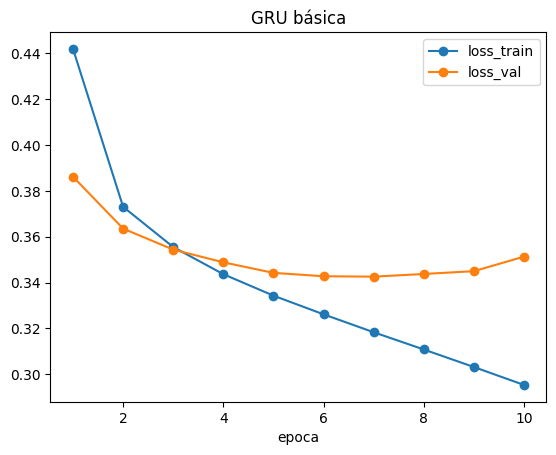

In [79]:
# Hiperparámetros de la RNN con GRU
HIDDEN_DIM = 256
EPOCAS = 10
LR = 1e-3

torch.manual_seed(SEED)
gru_basica = Basic1LayerGRU(hidden_dim=HIDDEN_DIM)
historial_gru_basica = cargar_o_entrenar(
    gru_basica, LossBasica(), "gru_basica_1_capa", epocas=EPOCAS, lr=LR, titulo="GRU básica"
)

In [80]:
predictor_gru_basica = PredictorRNN(gru_basica)

In [81]:
validar_nn(predictor_gru_basica, df_val_tokens)

Salida,Clase,Peso,Umbral
punt_inicial,¿,2.82,P(¿) > 0.262
capitalizacion_token,Inicial mayúscula,1.41,
capitalizacion_token,MAYÚSCULAS,2.24,
punt_final,.,2.51,
punt_final,",",2.51,
punt_final,?,3.98,


,Tarea,Clase,Etiqueta,F1 sin ajuste,F1 con umbral
0,punt_final,0,Sin signo,0.961,0.958
1,punt_final,1,.,0.322,0.416
2,punt_final,2,",",0.340,0.390
3,punt_final,3,?,0.312,0.400
4,punt_final,Macro,Promedio no ponderado,0.484,0.541
5,capitalizacion,0,minúsculas,0.969,0.968
6,capitalizacion,1,Inicial mayúscula,0.745,0.751
7,capitalizacion,2,Mixta,0.088,0.097
8,capitalizacion,3,MAYÚSCULAS,0.772,0.815
9,capitalizacion,Macro,Promedio no ponderado,0.644,0.658


###### Kendall - Gru

Modelo cargado desde modelos/gru_kendall_basica_1_capa.pt


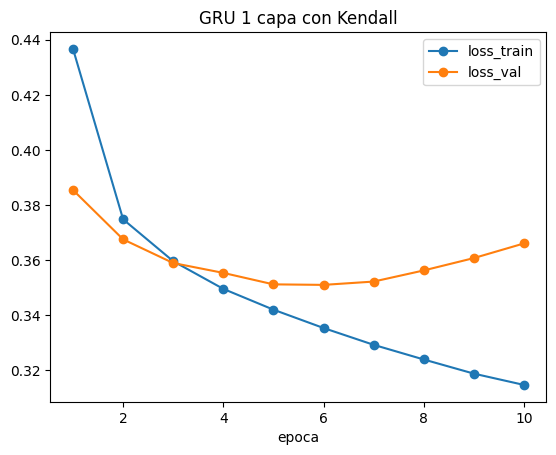

In [82]:
# Hiperparámetros de la RNN con GRU y Kendall
HIDDEN_DIM = 256
EPOCAS = 10
LR = 1e-3   

torch.manual_seed(SEED)
gru_kendall_1 = Basic1LayerGRU(hidden_dim=HIDDEN_DIM)
historial_gru_kendall_1 = cargar_o_entrenar(
    gru_kendall_1, LossKendall(), "gru_kendall_basica_1_capa", epocas=EPOCAS, lr=LR, titulo="GRU 1 capa con Kendall"
)

In [83]:
predictor_gru_kendall_1 = PredictorRNN(gru_kendall_1)

In [84]:
validar_nn(predictor_gru_kendall_1, df_val_tokens)

Salida,Clase,Peso,Umbral
punt_inicial,¿,3.98,P(¿) > 0.201
capitalizacion_token,Inicial mayúscula,1.41,
capitalizacion_token,MAYÚSCULAS,1.58,
punt_final,.,2.82,
punt_final,",",3.16,
punt_final,?,5.62,


,Tarea,Clase,Etiqueta,F1 sin ajuste,F1 con umbral
0,punt_final,0,Sin signo,0.960,0.954
1,punt_final,1,.,0.246,0.378
2,punt_final,2,",",0.304,0.370
3,punt_final,3,?,0.245,0.352
4,punt_final,Macro,Promedio no ponderado,0.439,0.514
5,capitalizacion,0,minúsculas,0.968,0.967
6,capitalizacion,1,Inicial mayúscula,0.732,0.739
7,capitalizacion,2,Mixta,0.106,0.102
8,capitalizacion,3,MAYÚSCULAS,0.764,0.781
9,capitalizacion,Macro,Promedio no ponderado,0.643,0.647


##### 2 capas

Dos capas recurrentes simples apiladas: la segunda lee la secuencia de estados de la primera. También leen solo de izquierda a derecha.

In [85]:
# Usamos ADAM para mayor velocidad de convergencia
# La entrada es un embedding de 768 dimensiones (BERT) por token y la salida son DIM_SALIDA logits POR TOKEN
# (3 tareas: 1 logit para ¿ (binaria), 3 para capitalización del token y 4 para puntuación final)
# Es many-to-many sincronizado: en cada paso t se emite la predicción del token t.
class Basic2LayerRNN(torch.nn.Module):
    def __init__(self, hidden_dim, input_dim=768, output_dim=DIM_SALIDA):
        super().__init__()

        self.hidden_dim = hidden_dim
        self.input_dim = input_dim
        self.output_dim = output_dim

        # Capa recurrente 1
        self.W1 = nn.Linear(input_dim, hidden_dim, bias=True)
        self.U1 = nn.Linear(hidden_dim, hidden_dim, bias=False)
        self.tanh = nn.Tanh()

        # Capa recurrente 2
        self.W2 = nn.Linear(hidden_dim, hidden_dim, bias=True)
        self.U2 = nn.Linear(hidden_dim, hidden_dim, bias=False)

        # Salida
        self.V = nn.Linear(hidden_dim, output_dim, bias=True)

        # Estado inicial entrenable para cada capa
        self.h01 = nn.Parameter(torch.zeros(1, hidden_dim))
        self.h02 = nn.Parameter(torch.zeros(1, hidden_dim))

    def forward(self, x):  # batch_size, seq_len, input_dim
        batch_size, seq_len, _ = x.shape

        h1 = self.h01.expand(batch_size, -1)
        h2 = self.h02.expand(batch_size, -1)

        # Capa 1
        Wx1 = self.W1(x)
        estados1 = []
        for t in range(seq_len):
            h1 = self.tanh(Wx1[:, t, :] + self.U1(h1))  # batch_size, hidden_dim
            estados1.append(h1)
        h1_seq = torch.stack(estados1, dim=1)  # batch_size, seq_len, hidden_dim

        # Capa 2
        Wx2 = self.W2(h1_seq)
        estados2 = []
        for t in range(seq_len):
            h2 = self.tanh(Wx2[:, t, :] + self.U2(h2))  # batch_size, hidden_dim
            estados2.append(h2)
        h2_seq = torch.stack(estados2, dim=1)  # batch_size, seq_len, hidden_dim

        # Salida final
        return self.V(h2_seq)  # batch_size, seq_len, output_dim

###### Pérdida básica

In [86]:
# Hiperparámetros de la RNN básica 2 capas
HIDDEN_DIM = 256
EPOCAS = 50
LR = 1e-3

torch.manual_seed(SEED)
rnn_basica_2 = Basic2LayerRNN(hidden_dim=HIDDEN_DIM)
historial_rnn_basica_2 = cargar_o_entrenar(
    rnn_basica_2, LossBasica(), "rnn_basica_2_capas", epocas=EPOCAS, lr=LR, titulo="RNN básica 2 capas"
)

Modelo cargado desde modelos/rnn_basica_2_capas.pt
No hay historial guardado en historial_rnn/rnn_basica_2_capas.csv


In [87]:
predictor_rnn_basica_2 = PredictorRNN(rnn_basica_2)

In [88]:
validar_nn(predictor_rnn_basica_2, df_val_tokens)

Salida,Clase,Peso,Umbral
punt_inicial,¿,2.51,P(¿) > 0.285
capitalizacion_token,Inicial mayúscula,1.41,
capitalizacion_token,MAYÚSCULAS,3.16,
punt_final,.,2.00,
punt_final,",",2.82,
punt_final,?,5.01,


,Tarea,Clase,Etiqueta,F1 sin ajuste,F1 con umbral
0,punt_final,0,Sin signo,0.961,0.957
1,punt_final,1,.,0.307,0.388
2,punt_final,2,",",0.304,0.369
3,punt_final,3,?,0.281,0.361
4,punt_final,Macro,Promedio no ponderado,0.463,0.519
5,capitalizacion,0,minúsculas,0.968,0.967
6,capitalizacion,1,Inicial mayúscula,0.740,0.744
7,capitalizacion,2,Mixta,0.112,0.090
8,capitalizacion,3,MAYÚSCULAS,0.739,0.788
9,capitalizacion,Macro,Promedio no ponderado,0.640,0.647


###### Kendall

In [89]:
# Hiperparámetros de la RNN básica con Kendall (mismos que la básica, para comparar solo la pérdida)
HIDDEN_DIM = 256
EPOCAS = 50
LR = 1e-3

torch.manual_seed(SEED)
rnn_kendall_2 = Basic2LayerRNN(hidden_dim=HIDDEN_DIM)
historial_rnn_kendall_2 = cargar_o_entrenar(
    rnn_kendall_2, LossKendall(), "rnn_kendall_2_capas", epocas=EPOCAS, lr=LR, titulo="RNN básica 2 capas con Kendall"
)

Modelo cargado desde modelos/rnn_kendall_2_capas.pt
No hay historial guardado en historial_rnn/rnn_kendall_2_capas.csv


In [90]:
predictor_rnn_kendall_2 = PredictorRNN(rnn_kendall_2)

In [91]:
validar_nn(predictor_rnn_kendall_2, df_val_tokens)

Salida,Clase,Peso,Umbral
punt_inicial,¿,2.24,P(¿) > 0.309
capitalizacion_token,Inicial mayúscula,1.78,
capitalizacion_token,MAYÚSCULAS,1.26,
punt_final,.,3.16,
punt_final,",",3.98,
punt_final,?,3.98,


,Tarea,Clase,Etiqueta,F1 sin ajuste,F1 con umbral
0,punt_final,0,Sin signo,0.959,0.953
1,punt_final,1,.,0.167,0.348
2,punt_final,2,",",0.273,0.349
3,punt_final,3,?,0.234,0.317
4,punt_final,Macro,Promedio no ponderado,0.408,0.492
5,capitalizacion,0,minúsculas,0.966,0.964
6,capitalizacion,1,Inicial mayúscula,0.707,0.724
7,capitalizacion,2,Mixta,0.098,0.094
8,capitalizacion,3,MAYÚSCULAS,0.749,0.770
9,capitalizacion,Macro,Promedio no ponderado,0.630,0.638


#### 6.2 Bidireccionales

##### 1 capa

Una pasada de izquierda a derecha y otra de derecha a izquierda; la salida de cada token combina las dos, así que ve también los tokens siguientes. Hay tres tipos de celda: RNN simple, LSTM y GRU.

In [92]:
# Usamos ADAM para mayor velocidad de convergencia
# La entrada es un embedding de 768 dimensiones (BERT) por token y la salida son DIM_SALIDA logits POR TOKEN
# (3 tareas: 1 logit para ¿ (binaria), 3 para capitalización del token y 4 para puntuación final)
# Es many-to-many sincronizado: en cada paso t se emite la predicción del token t.
class Bidirectional1LayerRNN(torch.nn.Module):
    def __init__(self, hidden_dim, input_dim=768, output_dim=DIM_SALIDA):
        super().__init__()

        self.hidden_dim = hidden_dim
        self.input_dim = input_dim
        self.output_dim = output_dim

        # Direcciones forward y backward
        self.W_f = nn.Linear(input_dim, hidden_dim, bias=True)
        self.U_f = nn.Linear(hidden_dim, hidden_dim, bias=False)
        self.W_b = nn.Linear(input_dim, hidden_dim, bias=True)
        self.U_b = nn.Linear(hidden_dim, hidden_dim, bias=False)

        # Concatenamos los estados forward y backward antes de la salida
        self.V = nn.Linear(hidden_dim * 2, output_dim, bias=True)
        self.tanh = nn.Tanh()

        self.h0_f = nn.Parameter(torch.zeros(1, hidden_dim))
        self.h0_b = nn.Parameter(torch.zeros(1, hidden_dim))

    def forward(self, x):
        batch_size, seq_len, _ = x.shape

        h_f = self.h0_f.expand(batch_size, -1)
        h_b = self.h0_b.expand(batch_size, -1)

        Wx_f = self.W_f(x)
        Wx_b = self.W_b(x)

        estados_f = []
        for t in range(seq_len):
            h_f = self.tanh(Wx_f[:, t, :] + self.U_f(h_f))
            estados_f.append(h_f)

        estados_b = []
        for t in range(seq_len - 1, -1, -1):
            h_b = self.tanh(Wx_b[:, t, :] + self.U_b(h_b))
            estados_b.append(h_b)

        h_f_seq = torch.stack(estados_f, dim=1)      # batch_size, seq_len, hidden_dim
        h_b_seq = torch.stack(list(reversed(estados_b)), dim=1)  # batch_size, seq_len, hidden_dim

        return self.V(torch.cat([h_f_seq, h_b_seq], dim=-1))

In [93]:
# Usamos ADAM para mayor velocidad de convergencia
# La entrada es un embedding de 768 dimensiones (BERT) por token y la salida son DIM_SALIDA logits POR TOKEN
# (3 tareas: 1 logit para ¿ (binaria), 3 para capitalización del token y 4 para puntuación final)
# Es many-to-many sincronizado: en cada paso t se emite la predicción del token t.
class Bidirectional1LayerLSTM(torch.nn.Module):
    def __init__(self, hidden_dim, input_dim=768, output_dim=DIM_SALIDA):
        super().__init__()

        self.hidden_dim = hidden_dim
        self.input_dim = input_dim
        self.output_dim = output_dim

        # LSTM forward
        # Cada una genera 4 gates: input, forget, candidate, output
        self.W_f = nn.Linear(input_dim, 4 * hidden_dim, bias=True)
        self.U_f = nn.Linear(hidden_dim, 4 * hidden_dim, bias=False)
        self.W_b = nn.Linear(input_dim, 4 * hidden_dim, bias=True)
        self.U_b = nn.Linear(hidden_dim, 4 * hidden_dim, bias=False)

        # Salida final sobre el concat de h_fwd y h_bwd
        self.V = nn.Linear(hidden_dim * 2, output_dim, bias=True)

        # Estado inicial para cada dirección
        self.h0_f = nn.Parameter(torch.zeros(1, hidden_dim))
        self.c0_f = nn.Parameter(torch.zeros(1, hidden_dim))
        self.h0_b = nn.Parameter(torch.zeros(1, hidden_dim))
        self.c0_b = nn.Parameter(torch.zeros(1, hidden_dim))

    def forward(self, x):
        batch_size, seq_len, _ = x.shape

        h_f = self.h0_f.expand(batch_size, -1)
        c_f = self.c0_f.expand(batch_size, -1)
        h_b = self.h0_b.expand(batch_size, -1)
        c_b = self.c0_b.expand(batch_size, -1)

        estados_f = []
        for t in range(seq_len):
            gates_f = self.W_f(x[:, t, :]) + self.U_f(h_f)
            i_f, f_f, g_f, o_f = gates_f.chunk(4, dim=-1)

            i_f = torch.sigmoid(i_f)
            f_f = torch.sigmoid(f_f)
            g_f = torch.tanh(g_f)
            o_f = torch.sigmoid(o_f)

            c_f = f_f * c_f + i_f * g_f
            h_f = o_f * torch.tanh(c_f)

            estados_f.append(h_f)

        estados_b = []
        for t in range(seq_len - 1, -1, -1):
            gates_b = self.W_b(x[:, t, :]) + self.U_b(h_b)
            i_b, f_b, g_b, o_b = gates_b.chunk(4, dim=-1)

            i_b = torch.sigmoid(i_b)
            f_b = torch.sigmoid(f_b)
            g_b = torch.tanh(g_b)
            o_b = torch.sigmoid(o_b)

            c_b = f_b * c_b + i_b * g_b
            h_b = o_b * torch.tanh(c_b)

            estados_b.append(h_b)

        h_f_seq = torch.stack(estados_f, dim=1)      # (batch, seq_len, hidden_dim)
        h_b_seq = torch.stack(list(reversed(estados_b)), dim=1)  # (batch, seq_len, hidden_dim)

        return self.V(torch.cat([h_f_seq, h_b_seq], dim=-1))

In [94]:
class Bidirectional1LayerGRU(nn.Module):
    """
    Red Neuronal Recurrente Bidireccional con celdas GRU.
    Entrada: (batch_size, seq_len, 768) - Embeddings estáticos de BERT.
    Salida: (batch_size, seq_len, DIM_SALIDA) - Logits por token.
    """
    def __init__(self, hidden_dim, input_dim=768, output_dim=DIM_SALIDA):
        super().__init__()

        self.hidden_dim = hidden_dim
        self.input_dim = input_dim
        self.output_dim = output_dim

        # Capa GRU Bidireccional: PyTorch procesa ambas direcciones internamente en CUDA/C++
        self.gru = nn.GRU(
            input_size=input_dim,
            hidden_size=hidden_dim,
            num_layers=1,
            batch_first=True,
            bidirectional=True
        )

        # Capa Lineal de Salida: al concatenar forward (hidden_dim) y backward (hidden_dim),
        # la entrada a la capa lineal pasa a ser hidden_dim * 2.
        self.fc_out = nn.Linear(hidden_dim * 2, output_dim)

    def forward(self, x):
        # x shape: (batch_size, seq_len, input_dim)
        batch_size = x.size(0)

        # h0 requiere dimensión (num_layers * num_directions, batch_size, hidden_dim) = (2, batch_size, hidden_dim)
        h0 = torch.zeros(2, batch_size, self.hidden_dim, device=x.device)

        # rnn_out contiene la concatenación de los estados ocultos forward y backward para cada token t
        # rnn_out shape: (batch_size, seq_len, hidden_dim * 2)
        rnn_out, _ = self.gru(x, h0)

        # Proyección lineal a los logits de salida por token
        # logits shape: (batch_size, seq_len, output_dim)
        logits = self.fc_out(rnn_out)

        return logits

###### RNN simple · pérdida básica

In [95]:
# Hiperparámetros de la RNN Bidireccional
HIDDEN_DIM = 256
EPOCAS = 50
LR = 1e-3

torch.manual_seed(SEED)
rnn_bi = Bidirectional1LayerRNN(hidden_dim=HIDDEN_DIM)
historial_rnn_bi = cargar_o_entrenar(
    rnn_bi, LossBasica(), "rnn_bi_1_capa", epocas=EPOCAS, lr=LR, titulo="RNN Bidireccional 1 capa"
)

Modelo cargado desde modelos/rnn_bi_1_capa.pt
No hay historial guardado en historial_rnn/rnn_bi_1_capa.csv


In [96]:
predictor_rnn_bi = PredictorRNN(rnn_bi)

In [97]:
validar_nn(predictor_rnn_bi, df_val_tokens)

Salida,Clase,Peso,Umbral
punt_inicial,¿,2.00,P(¿) > 0.334
capitalizacion_token,Inicial mayúscula,1.41,
capitalizacion_token,MAYÚSCULAS,2.00,
punt_final,.,0.89,
punt_final,",",1.58,
punt_final,?,2.82,


,Tarea,Clase,Etiqueta,F1 sin ajuste,F1 con umbral
0,punt_final,0,Sin signo,0.977,0.977
1,punt_final,1,.,0.702,0.688
2,punt_final,2,",",0.518,0.551
3,punt_final,3,?,0.419,0.477
4,punt_final,Macro,Promedio no ponderado,0.654,0.673
5,capitalizacion,0,minúsculas,0.976,0.975
6,capitalizacion,1,Inicial mayúscula,0.803,0.806
7,capitalizacion,2,Mixta,0.160,0.184
8,capitalizacion,3,MAYÚSCULAS,0.832,0.849
9,capitalizacion,Macro,Promedio no ponderado,0.693,0.704


###### RNN simple · Kendall

In [98]:
# Hiperparámetros de la RNN Bidireccional
HIDDEN_DIM = 256
EPOCAS = 50
LR = 1e-3

torch.manual_seed(SEED)
rnn_bi_kendall = Bidirectional1LayerRNN(hidden_dim=HIDDEN_DIM)
historial_rnn_bi_kendall = cargar_o_entrenar(
    rnn_bi_kendall, LossKendall(), "rnn_bi_kendall_1_capa", epocas=EPOCAS, lr=LR, titulo="RNN Bidireccional 1 capa con Kendall"
)

Modelo cargado desde modelos/rnn_bi_kendall_1_capa.pt
No hay historial guardado en historial_rnn/rnn_bi_kendall_1_capa.csv


In [99]:
predictor_rnn_kendall_bi_1 = PredictorRNN(rnn_bi_kendall)

In [100]:
validar_nn(predictor_rnn_kendall_bi_1, df_val_tokens)

Salida,Clase,Peso,Umbral
punt_inicial,¿,1.41,P(¿) > 0.415
capitalizacion_token,Inicial mayúscula,2.51,
capitalizacion_token,MAYÚSCULAS,5.01,
punt_final,.,0.89,
punt_final,",",2.24,
punt_final,?,2.51,


,Tarea,Clase,Etiqueta,F1 sin ajuste,F1 con umbral
0,punt_final,0,Sin signo,0.974,0.974
1,punt_final,1,.,0.664,0.645
2,punt_final,2,",",0.441,0.511
3,punt_final,3,?,0.370,0.426
4,punt_final,Macro,Promedio no ponderado,0.613,0.639
5,capitalizacion,0,minúsculas,0.973,0.972
6,capitalizacion,1,Inicial mayúscula,0.765,0.783
7,capitalizacion,2,Mixta,0.125,0.135
8,capitalizacion,3,MAYÚSCULAS,0.761,0.823
9,capitalizacion,Macro,Promedio no ponderado,0.656,0.678


###### LSTM · pérdida básica

In [101]:
# Hiperparámetros de la RNN Bidireccional
HIDDEN_DIM = 256
EPOCAS = 50
LR = 1e-3

torch.manual_seed(SEED)
rnn_bi_lstm_basica = Bidirectional1LayerLSTM(hidden_dim=HIDDEN_DIM)
historial_rnn_bi_lstm_basica = cargar_o_entrenar(
    rnn_bi_lstm_basica, LossBasica(), "rnn_bi_lstm_basica_1_capa", epocas=EPOCAS, lr=LR, titulo="LSTM Bidireccional 1 capa"
)

Modelo cargado desde modelos/rnn_bi_lstm_basica_1_capa.pt
No hay historial guardado en historial_rnn/rnn_bi_lstm_basica_1_capa.csv


In [102]:
predictor_rnn_bi_lstm_basica = PredictorRNN(rnn_bi_lstm_basica)

In [103]:
# LSTM Bidireccional 1 capa, evaluada en validación
validar_nn(predictor_rnn_bi_lstm_basica, df_val_tokens)

Salida,Clase,Peso,Umbral
punt_inicial,¿,1.58,P(¿) > 0.387
capitalizacion_token,Inicial mayúscula,1.41,
capitalizacion_token,MAYÚSCULAS,1.12,
punt_final,.,0.89,
punt_final,",",2.24,
punt_final,?,2.00,


,Tarea,Clase,Etiqueta,F1 sin ajuste,F1 con umbral
0,punt_final,0,Sin signo,0.979,0.979
1,punt_final,1,.,0.741,0.731
2,punt_final,2,",",0.549,0.603
3,punt_final,3,?,0.522,0.554
4,punt_final,Macro,Promedio no ponderado,0.698,0.717
5,capitalizacion,0,minúsculas,0.979,0.979
6,capitalizacion,1,Inicial mayúscula,0.828,0.833
7,capitalizacion,2,Mixta,0.156,0.146
8,capitalizacion,3,MAYÚSCULAS,0.873,0.874
9,capitalizacion,Macro,Promedio no ponderado,0.709,0.708


###### LSTM · Kendall

In [104]:
# Hiperparámetros de la RNN Bidireccional
HIDDEN_DIM = 256
EPOCAS = 50
LR = 1e-3

torch.manual_seed(SEED)
rnn_bi_lstm_kendall = Bidirectional1LayerLSTM(hidden_dim=HIDDEN_DIM)
historial_rnn_bi_lstm_kendall = cargar_o_entrenar(
    rnn_bi_lstm_kendall, LossKendall(), "rnn_bi_lstm_kendall_1_capa", epocas=EPOCAS, lr=LR, titulo="LSTM Bidireccional 1 capa con Kendall"
)

Modelo cargado desde modelos/rnn_bi_lstm_kendall_1_capa.pt
No hay historial guardado en historial_rnn/rnn_bi_lstm_kendall_1_capa.csv


In [105]:
predictor_rnn_bi_lstm_kendall = PredictorRNN(rnn_bi_lstm_kendall)

In [106]:
# LSTM Bidireccional 1 capa con Kendall, evaluada en validación
validar_nn(predictor_rnn_bi_lstm_kendall, df_val_tokens)

Salida,Clase,Peso,Umbral
punt_inicial,¿,1.58,P(¿) > 0.387
capitalizacion_token,Inicial mayúscula,1.12,
capitalizacion_token,MAYÚSCULAS,1.78,
punt_final,.,1.12,
punt_final,",",1.78,
punt_final,?,2.24,


,Tarea,Clase,Etiqueta,F1 sin ajuste,F1 con umbral
0,punt_final,0,Sin signo,0.978,0.977
1,punt_final,1,.,0.715,0.707
2,punt_final,2,",",0.532,0.563
3,punt_final,3,?,0.483,0.506
4,punt_final,Macro,Promedio no ponderado,0.677,0.688
5,capitalizacion,0,minúsculas,0.978,0.978
6,capitalizacion,1,Inicial mayúscula,0.820,0.821
7,capitalizacion,2,Mixta,0.148,0.161
8,capitalizacion,3,MAYÚSCULAS,0.850,0.864
9,capitalizacion,Macro,Promedio no ponderado,0.699,0.706


###### GRU · pérdida básica

In [107]:
# Hiperparámetros de la GRU Bidireccional
HIDDEN_DIM = 256
EPOCAS = 50
LR = 1e-3

torch.manual_seed(SEED)
rnn_bi_gru = Bidirectional1LayerGRU(hidden_dim=HIDDEN_DIM)
historial_rnn_bi_gru = cargar_o_entrenar(
    rnn_bi_gru, LossBasica(), "rnn_bi_gru_1_capa", epocas=EPOCAS, lr=LR, titulo="GRU Bidireccional 1 capa"
)

Modelo cargado desde modelos/rnn_bi_gru_1_capa.pt
No hay historial guardado en historial_rnn/rnn_bi_gru_1_capa.csv


In [108]:
predictor_rnn_bi_gru = PredictorRNN(rnn_bi_gru)

In [109]:
# GRU Bidireccional 1 capa, evaluada en validación
validar_nn(predictor_rnn_bi_gru, df_val_tokens)

Salida,Clase,Peso,Umbral
punt_inicial,¿,1.12,P(¿) > 0.471
capitalizacion_token,Inicial mayúscula,1.26,
capitalizacion_token,MAYÚSCULAS,1.78,
punt_final,.,1.00,
punt_final,",",1.78,
punt_final,?,1.58,


,Tarea,Clase,Etiqueta,F1 sin ajuste,F1 con umbral
0,punt_final,0,Sin signo,0.979,0.979
1,punt_final,1,.,0.734,0.725
2,punt_final,2,",",0.565,0.593
3,punt_final,3,?,0.511,0.522
4,punt_final,Macro,Promedio no ponderado,0.698,0.705
5,capitalizacion,0,minúsculas,0.979,0.978
6,capitalizacion,1,Inicial mayúscula,0.826,0.827
7,capitalizacion,2,Mixta,0.172,0.178
8,capitalizacion,3,MAYÚSCULAS,0.865,0.876
9,capitalizacion,Macro,Promedio no ponderado,0.710,0.715


###### GRU · Kendall

In [110]:
# Hiperparámetros de la GRU Bidireccional con Kendall (mismos que la GRU con pérdida básica)
HIDDEN_DIM = 256
EPOCAS = 50
LR = 1e-3

torch.manual_seed(SEED)
rnn_bi_gru_kendall = Bidirectional1LayerGRU(hidden_dim=HIDDEN_DIM)
historial_rnn_bi_gru_kendall = cargar_o_entrenar(
    rnn_bi_gru_kendall, LossKendall(), "rnn_bi_gru_kendall_1_capa", epocas=EPOCAS, lr=LR, titulo="GRU Bidireccional 1 capa con Kendall"
)

Modelo cargado desde modelos/rnn_bi_gru_kendall_1_capa.pt
No hay historial guardado en historial_rnn/rnn_bi_gru_kendall_1_capa.csv


In [111]:
predictor_rnn_bi_gru_kendall = PredictorRNN(rnn_bi_gru_kendall)

In [112]:
# GRU Bidireccional 1 capa con Kendall, evaluada en validación
validar_nn(predictor_rnn_bi_gru_kendall, df_val_tokens)

Salida,Clase,Peso,Umbral
punt_inicial,¿,2.00,P(¿) > 0.334
capitalizacion_token,Inicial mayúscula,2.00,
capitalizacion_token,MAYÚSCULAS,3.16,
punt_final,.,1.12,
punt_final,",",2.00,
punt_final,?,2.24,


,Tarea,Clase,Etiqueta,F1 sin ajuste,F1 con umbral
0,punt_final,0,Sin signo,0.977,0.978
1,punt_final,1,.,0.713,0.701
2,punt_final,2,",",0.517,0.565
3,punt_final,3,?,0.461,0.493
4,punt_final,Macro,Promedio no ponderado,0.667,0.684
5,capitalizacion,0,minúsculas,0.977,0.977
6,capitalizacion,1,Inicial mayúscula,0.802,0.817
7,capitalizacion,2,Mixta,0.162,0.165
8,capitalizacion,3,MAYÚSCULAS,0.833,0.860
9,capitalizacion,Macro,Promedio no ponderado,0.693,0.705


### 7. Comparación de modelos

F1 por token en validación de todas las redes de la sección 6, una columna por modelo, con los umbrales ajustados en validación (el "F1 con umbral" de `validar_nn`). En cada fila, el mejor valor está en negrita.

- **Resumen:** F1 macro de cada tarea y el promedio de las tres.
- **Detalle:** F1 de cada clase de cada tarea.
- **Umbrales:** el peso elegido para cada clase en cada modelo.

In [113]:
# Todos los modelos, en el orden de la sección 6
predictores = {
    "Uni 1c · básica": predictor_rnn_basica,
    "Uni 1c · Kendall": predictor_rnn_kendall_1,
    "Uni 1c · GRU básica": predictor_gru_basica,
    "Uni 1c · GRU Kendall": predictor_gru_kendall_1,
    "Uni 2c · básica": predictor_rnn_basica_2,
    "Uni 2c · Kendall": predictor_rnn_kendall_2,
    "Bi 1c · RNN básica": predictor_rnn_bi,
    "Bi 1c · RNN Kendall": predictor_rnn_kendall_bi_1,
    "Bi 1c · LSTM básica": predictor_rnn_bi_lstm_basica,
    "Bi 1c · LSTM Kendall": predictor_rnn_bi_lstm_kendall,
    "Bi 1c · GRU básica": predictor_rnn_bi_gru,
    "Bi 1c · GRU Kendall": predictor_rnn_bi_gru_kendall,
}

# F1 de cada modelo en validación (por token): una columna por modelo
reales = ordenar_tokens(df_val_tokens)
f1_por_modelo = {}
for nombre, predictor in predictores.items():
    if predictor.pesos is None:  # si no se corrió su validar_nn
        predictor.ajustar_umbrales(df_val_tokens)
    prediccion = predictor.predecir(df_val_tokens)
    tabla = tabla_f1(reales[TAREAS], prediccion[TAREAS])
    f1_por_modelo[nombre] = tabla.set_index(["Tarea", "Etiqueta"])["F1"]
comparacion = pd.DataFrame(f1_por_modelo)

# Resumen: F1 macro de cada tarea y el promedio de las tres
resumen = comparacion.xs("Promedio no ponderado", level="Etiqueta").copy()
resumen.loc["Promedio de las 3 tareas"] = resumen.mean()

(
    resumen.style
    .format("{:.3f}")
    .background_gradient(cmap="YlGn", vmin=0, vmax=1, axis=None)
    .highlight_max(axis=1, props="font-weight: bold")
    .set_caption("F1 macro por tarea en validación")
)

,Uni 1c · básica,Uni 1c · Kendall,Uni 1c · GRU básica,Uni 1c · GRU Kendall,Uni 2c · básica,Uni 2c · Kendall,Bi 1c · RNN básica,Bi 1c · RNN Kendall,Bi 1c · LSTM básica,Bi 1c · LSTM Kendall,Bi 1c · GRU básica,Bi 1c · GRU Kendall
Tarea,,,,,,,,,,,,
punt_final,0.514,0.489,0.541,0.514,0.519,0.492,0.673,0.639,0.717,0.688,0.705,0.684
capitalizacion,0.638,0.629,0.658,0.647,0.647,0.638,0.704,0.678,0.708,0.706,0.715,0.705
punt_inicial,0.744,0.754,0.750,0.765,0.751,0.750,0.818,0.842,0.839,0.866,0.832,0.860
Promedio de las 3 tareas,0.632,0.624,0.649,0.642,0.639,0.627,0.732,0.720,0.755,0.753,0.750,0.750


In [120]:
# Detalle: F1 de cada clase de cada tarea
(
    comparacion.style
    .format("{:.3f}")
    .background_gradient(cmap="YlGn", vmin=0, vmax=1, axis=None)
    .highlight_max(axis=1, props="font-weight: bold")
    .set_caption("F1 por clase en validación")
)

In [121]:
# Umbrales: peso elegido para cada clase en cada modelo (1 = sin cambio; en ¿, umbral = 1 / (1 + peso))
umbrales = pd.DataFrame({
    nombre: tabla_umbrales(predictor.pesos).set_index(["Salida", "Clase"])["Peso"]
    for nombre, predictor in predictores.items()
})
umbrales.style.format("{:.2f}").set_caption("Pesos de umbral elegidos en validación")

#### Ejemplos con un modelo

`predictor_ejemplos` es el modelo que se usa en los ejemplos: la tabla token por token de una instancia de validación, las mismas oraciones que con Random Forest y el CSV de entrega. **Cambiarlo por el modelo que elijamos.**

In [122]:
# Modelo para los ejemplos: cambiarlo por el que elijamos
predictor_ejemplos = predictor_rnn_basica

In [123]:
# Qué pasa token por token en una instancia de validación
prediccion_val = predictor_ejemplos.predecir(df_val_tokens)
instancia_val = prediccion_val["instancia_id"].iloc[0]

predictor_ejemplos.mostrar(prediccion_val, instancia_val)
print("Texto real:    ", df_instancias.set_index("instancia_id").loc[instancia_val, "texto"])

 palabra    token ¿ fin  cap token  escrito  cap palabra
       0      sus                0      sus            0
       1    señor                1    Señor            1
       1    ##ías     ,          0      ías            1
       2      han                0      han            0
       3     soli                0     soli            0
       3   ##cita                0     cita            0
       3     ##do                0       do            0
       4       un                0       un            0
       5   debate                0   debate            0
       6    sobre                0    sobre            0
       7       el                0       el            0
       8     tema                0     tema            0
       9     para                0     para            0
      10      los                0      los            0
      11 próximos                0 próximos            0
      12     días     .          0     días            0

Texto predicho: sus Señorías, 

In [124]:
# Formato del CSV de entrega
formato_entrega(prediccion_val).head(15)

,instancia_id,token_id,token,punt_inicial,punt_final,capitalización
0,2,10846,sus,,,0
1,2,47599,señor,,,1
2,2,19058,##ías,,",",1
3,2,10279,han,,,0
4,2,36766,soli,,,0
5,2,32502,##cita,,,0
6,2,10317,##do,,,0
7,2,10119,un,,,0
8,2,29632,debate,,,0
9,2,10690,sobre,,,0


## Elección del modelo final y evaluación en control

Se comparan **todos** los modelos (las redes de la sección 6 y las variantes de Random Forest) en las mismas condiciones, se elige el mejor y recién ahí se usa el conjunto de control, **una sola vez**.

- **Conjunto de comparación:** la validación de las redes (`df_val_tokens`) sin las instancias de los documentos de las primeras `ORACIONES_RF_POR_FUENTE` oraciones de cada fuente. Los RF entrenaron con parte de esos documentos (su `separar_validacion` se hizo sobre otro conjunto, así que eligió otros documentos), y evaluarlos ahí los favorecería.
- **Métrica: F1 macro por palabra.** El enunciado aclara que, aunque la entrega es por token, la evaluación es por palabra: una palabra de varios tokens no pesa más que una de un token. Cada palabra se cuenta una vez, con el `¿` de su primer token, el `. , ?` de su último token y la capitalización de su primer token. (Las secciones anteriores miden por token.)
- **Umbrales:** cada modelo ajusta sus umbrales de decisión en el conjunto de comparación (ver *Umbrales de decisión*); el F1 que se muestra es con umbral.
- **Elección:** el modelo con mayor promedio de los F1 macro de las 3 tareas. Sus umbrales quedan fijos (son de desarrollo) y con ellos se evalúa en control y se predice `datos_test.csv`.

### Herramientas

- `por_palabra(df_tokens, prediccion)`: de etiquetas y predicciones por token a una fila por palabra (como la evaluación oficial). Las palabras salen de las etiquetas (`instancia_id`, `posicion_palabra`), así que reales y predichas quedan alineadas.
- `f1_por_palabra(predictor, df_tokens, ajustar_umbral)`: la tabla de F1 por palabra de un predictor (con `ajustar_umbral=True`, primero le ajusta los umbrales en `df_tokens`).
- `PredictorRF`: los Random Forest con la misma interfaz que `PredictorRNN` (`predecir`, `ajustar_umbrales`, `pesos`), así se comparan con el mismo código. Arma los atributos por lotes de instancias: con embeddings son 2304 columnas por palabra y no entran todas juntas en memoria.
- `VARIANTES_RF`: las 5 variantes de RF, con el archivo donde quedó guardada cada una y cómo arma sus atributos. Las columnas salen del modelo (`feature_names_in_`). Si una variante no está en disco, se saltea (hay que correr su sección).

In [125]:
def por_palabra(df_tokens, prediccion):
    """
    Etiquetas reales y predichas con una fila por palabra: ¿ del primer token, . , ? del último y
    capitalización del primero. prediccion: la salida de un predictor sobre df_tokens (mismo orden
    que ordenar_tokens(df_tokens)). Devuelve (reales, predichas), con una columna por tarea.
    """
    reales = ordenar_tokens(df_tokens)
    palabra = reales.groupby(["instancia_id", "posicion_palabra"], sort=False).ngroup().to_numpy()

    def resumir(df):
        grupos = df[TAREAS].reset_index(drop=True).groupby(palabra, sort=False)
        return pd.DataFrame({
            "punt_inicial": grupos["punt_inicial"].first(),
            "punt_final": grupos["punt_final"].last(),
            "capitalizacion": grupos["capitalizacion"].first(),
        })[TAREAS]

    return resumir(reales), resumir(prediccion)


def f1_por_palabra(predictor, df_tokens, ajustar_umbral):
    """Tabla de F1 por palabra (tabla_f1) de un PredictorRNN o PredictorRF sobre df_tokens."""
    if ajustar_umbral:
        datos, salida = predictor.ajustar_umbrales(df_tokens)  # el modelo corre una sola vez
        prediccion = predictor.armar_prediccion(datos, salida, predictor.pesos)
    else:
        prediccion = predictor.predecir(df_tokens)
    reales, predichas = por_palabra(df_tokens, prediccion)
    return tabla_f1(reales, predichas)


def resumen_macro(tablas):
    """{nombre: tabla_f1} -> F1 macro de cada tarea y el promedio de las 3, una columna por modelo."""
    resumen = pd.DataFrame({
        nombre: tabla[tabla["Clase"] == "Macro"].set_index("Tarea")["F1"] for nombre, tabla in tablas.items()
    })
    resumen.loc["Promedio de las 3 tareas"] = resumen.mean()
    return resumen


def estilo_resumen(resumen, titulo):
    return (
        resumen.style
        .format("{:.3f}")
        .background_gradient(cmap="YlGn", vmin=0, vmax=1, axis=None)
        .highlight_max(axis=1, props="font-weight: bold")
        .set_caption(titulo)
    )


class PredictorRF:
    """
    Random Forest (uno por tarea, predicen por palabra) con la misma interfaz que PredictorRNN.
    armar_atributos: función que recibe palabras (instancia_id, posicion, palabra) y devuelve sus atributos.
    """

    def __init__(self, modelos, armar_atributos, instancias_por_lote=1000):
        self.modelos = modelos
        self.armar_atributos = armar_atributos
        self.instancias_por_lote = instancias_por_lote
        self.pesos = None  # pesos de umbral por tarea (ajustar_umbrales). None = argmax (= predict)

    def probabilidades(self, df_tokens):
        """Tokens ordenados (con palabra_id) y {tarea: (palabras, clases) probabilidades}; la fila i es la palabra i."""
        tokens = ordenar_tokens(df_tokens)
        tokens["palabra_id"] = numerar_palabras(tokens)
        palabras = tokens.groupby("palabra_id", sort=False).agg(
            instancia_id=("instancia_id", "first"),
            palabra=("token", lambda ts: "".join(t.removeprefix("##") for t in ts)),
        ).reset_index()
        palabras["posicion"] = palabras.groupby("instancia_id").cumcount()

        # Por lotes de instancias: los atributos de un lote se tiran apenas se usan
        probas = {tarea: [] for tarea in TAREAS}
        instancias = palabras["instancia_id"].unique()
        for inicio in range(0, len(instancias), self.instancias_por_lote):
            lote = palabras[palabras["instancia_id"].isin(instancias[inicio:inicio + self.instancias_por_lote])]
            atributos = self.armar_atributos(lote)  # mismo orden que lote: por (instancia_id, posicion)
            for tarea in TAREAS:
                modelo = self.modelos[tarea]
                probas[tarea].append(probas_por_clase(modelo, atributos[modelo.feature_names_in_], len(CLASES[tarea])))
        return tokens, {tarea: np.concatenate(partes) for tarea, partes in probas.items()}

    def ajustar_umbrales(self, df_tokens):
        """Ajusta self.pesos en df_tokens (con etiquetas), por palabra. Devuelve (tokens, probas)."""
        tokens, probas = self.probabilidades(df_tokens)
        palabras = tokens.groupby("palabra_id")
        reales = {
            "punt_inicial": palabras["punt_inicial"].first(),
            "punt_final": palabras["punt_final"].last(),
            "capitalizacion": palabras["capitalizacion"].first(),
        }
        self.pesos = {tarea: ajustar_pesos(probas[tarea], reales[tarea].to_numpy()) for tarea in TAREAS}
        return tokens, probas

    def armar_prediccion(self, tokens, probas, pesos):
        """Clase de cada palabra (con pesos, o argmax si es None) repartida en sus tokens, como predecir_por_token."""
        prediccion = tokens[["instancia_id", "posicion", "token_id", "token", "palabra_id"]].copy()
        for tarea in TAREAS:
            pesos_tarea = np.ones(probas[tarea].shape[1]) if pesos is None else pesos[tarea]
            prediccion[tarea] = decidir(probas[tarea], pesos_tarea)[prediccion["palabra_id"].to_numpy()]
        return puntuacion_en_bordes(prediccion)

    def predecir(self, df_tokens):
        tokens, probas = self.probabilidades(df_tokens)
        return self.armar_prediccion(tokens, probas, self.pesos)


# Variantes de RF: archivo en RUTA_MODELOS ({tarea} se reemplaza) y cómo arma sus atributos
VARIANTES_RF = {
    "RF atributos · sin ventana": ("rf_{tarea}_sin_v", lambda palabras: extraer_atributos(palabras, tamano_ventana=0)),
    "RF atributos · ventana 1": ("rf_{tarea}_v1", lambda palabras: extraer_atributos(palabras, tamano_ventana=1)),
    "RF atributos · ventana 2": ("rf_{tarea}", lambda palabras: extraer_atributos(palabras, tamano_ventana=2)),
    "RF embeddings · sin ventana": ("rf_emb_{tarea}_sin_v", lambda palabras: armar_dataframe_embeddings(palabras, ventana=0)),
    "RF embeddings · ventana 1": ("rf_emb_{tarea}", lambda palabras: armar_dataframe_embeddings(palabras, ventana=1)),
}


def cargar_rf(nombre):
    """PredictorRF de una variante de VARIANTES_RF, o None si sus archivos no están."""
    archivo, armar_atributos = VARIANTES_RF[nombre]
    rutas = {tarea: os.path.join(RUTA_MODELOS, archivo.format(tarea=tarea) + ".joblib") for tarea in TAREAS}
    if not all(os.path.exists(ruta) for ruta in rutas.values()):
        return None
    return PredictorRF({tarea: joblib.load(ruta) for tarea, ruta in rutas.items()}, armar_atributos)

### Conjunto de comparación

In [126]:
# Validación de las redes sin las instancias de documentos que pudo haber usado el RF
primera_oracion = df_instancias.set_index("instancia_id")["primera_oracion"]
sin_datos_rf = primera_oracion.reindex(df_val_tokens["instancia_id"]).to_numpy() >= ORACIONES_RF_POR_FUENTE
df_comparacion_tokens = df_val_tokens[sin_datos_rf]

print(f"Validación de las redes:  {df_val_tokens['instancia_id'].nunique()} instancias")
print(f"Conjunto de comparación:  {df_comparacion_tokens['instancia_id'].nunique()} instancias, "
      f"{len(df_comparacion_tokens)} tokens")

Validación de las redes:  24687 instancias
Conjunto de comparación:  23508 instancias, 694856 tokens


### Todas las redes

F1 macro por palabra de cada red de la sección 6 (`predictores`), con umbral ajustado en el conjunto de comparación.

In [127]:
f1_redes = {nombre: f1_por_palabra(predictor, df_comparacion_tokens, ajustar_umbral=True)
            for nombre, predictor in predictores.items()}
resumen_redes = resumen_macro(f1_redes)
estilo_resumen(resumen_redes, "Redes: F1 macro por palabra (con umbral)")

,Uni 1c · básica,Uni 1c · Kendall,Uni 1c · GRU básica,Uni 1c · GRU Kendall,Uni 2c · básica,Uni 2c · Kendall,Bi 1c · RNN básica,Bi 1c · RNN Kendall,Bi 1c · LSTM básica,Bi 1c · LSTM Kendall,Bi 1c · GRU básica,Bi 1c · GRU Kendall
Tarea,,,,,,,,,,,,
punt_final,0.511,0.486,0.538,0.511,0.516,0.488,0.673,0.637,0.716,0.686,0.705,0.684
capitalizacion,0.639,0.630,0.655,0.648,0.645,0.640,0.704,0.672,0.708,0.707,0.711,0.705
punt_inicial,0.745,0.755,0.750,0.766,0.753,0.752,0.819,0.842,0.839,0.867,0.833,0.860
Promedio de las 3 tareas,0.632,0.624,0.648,0.642,0.638,0.627,0.732,0.717,0.755,0.753,0.750,0.750


### Todos los Random Forest

Lo mismo para cada variante de RF guardada en disco. Se cargan de a una y se liberan después de evaluarlas (solo se guardan sus umbrales); la mejor se vuelve a cargar más abajo.

In [157]:
f1_rf, pesos_rf = {}, {}
for nombre in VARIANTES_RF:
    predictor_rf = cargar_rf(nombre)
    if predictor_rf is None:
        print(f"{nombre}: no está en {RUTA_MODELOS}, se saltea")
        continue
    f1_rf[nombre] = f1_por_palabra(predictor_rf, df_comparacion_tokens, ajustar_umbral=True)
    pesos_rf[nombre] = predictor_rf.pesos
    liberar("predictor_rf")

resumen_rf = resumen_macro(f1_rf)
estilo_resumen(resumen_rf, "Random Forest: F1 macro por palabra (con umbral)")

,RF atributos · sin ventana,RF atributos · ventana 1,RF atributos · ventana 2,RF embeddings · sin ventana,RF embeddings · ventana 1
Tarea,,,,,
punt_final,0.409,0.436,0.454,0.372,0.500
capitalizacion,0.414,0.426,0.427,0.523,0.568
punt_inicial,0.668,0.709,0.703,0.686,0.705
Promedio de las 3 tareas,0.497,0.524,0.528,0.527,0.591


### Mejor RF vs. mejor red

El mejor de cada familia según el promedio de las 3 tareas, junto al baseline (el dummy predice siempre la clase mayoritaria, 0, en las 3 tareas). El modelo final es el mejor de los dos.

In [158]:
mejor_red = resumen_redes.loc["Promedio de las 3 tareas"].idxmax()
mejor_rf = resumen_rf.loc["Promedio de las 3 tareas"].idxmax()

# Baseline: clase 0 en las 3 tareas
reales_comparacion, _ = por_palabra(df_comparacion_tokens, ordenar_tokens(df_comparacion_tokens))
f1_baseline = tabla_f1(reales_comparacion, pd.DataFrame(0, index=reales_comparacion.index, columns=TAREAS))

finalistas = {"Baseline (dummy)": f1_baseline, mejor_rf: f1_rf[mejor_rf], mejor_red: f1_redes[mejor_red]}
resumen_finalistas = resumen_macro(finalistas)
estilo_resumen(resumen_finalistas, "Baseline vs. mejor RF vs. mejor red: F1 macro por palabra (con umbral)")

,Baseline (dummy),RF embeddings · ventana 1,Bi 1c · LSTM básica
Tarea,,,
punt_final,0.235,0.500,0.716
capitalizacion,0.236,0.568,0.708
punt_inicial,0.498,0.705,0.839
Promedio de las 3 tareas,0.323,0.591,0.755


In [159]:
# Detalle por clase de los finalistas
detalle_finalistas = pd.DataFrame({
    nombre: tabla.set_index(["Tarea", "Etiqueta"])["F1"] for nombre, tabla in finalistas.items()
})
estilo_resumen(detalle_finalistas, "F1 por clase (por palabra) de los finalistas")

In [160]:
# Modelo final: el mejor de los dos, con sus umbrales de desarrollo
if resumen_finalistas.loc["Promedio de las 3 tareas", mejor_red] >= resumen_finalistas.loc["Promedio de las 3 tareas", mejor_rf]:
    nombre_final, predictor_final = mejor_red, predictores[mejor_red]
else:
    nombre_final, predictor_final = mejor_rf, cargar_rf(mejor_rf)
    predictor_final.pesos = pesos_rf[mejor_rf]

print("Modelo final:", nombre_final)
tabla_umbrales(predictor_final.pesos).style.format({"Peso": "{:.2f}"}).hide(axis="index").set_caption(
    "Umbrales del modelo final (ajustados en desarrollo)")

Modelo final: Bi 1c · LSTM básica


Salida,Clase,Peso,Umbral
punt_inicial,¿,1.78,P(¿) > 0.360
capitalizacion_token,Inicial mayúscula,1.41,
capitalizacion_token,MAYÚSCULAS,1.12,
punt_final,.,0.89,
punt_final,",",2.24,
punt_final,?,2.00,


### F1 según el contexto que ve el modelo

F1 macro promedio (por palabra, con umbral) de cada modelo, ordenados de menos a más contexto: ninguno (baseline), la palabra sola, una ventana de vecinas (RF), las palabras anteriores (RNN unidireccional) y las anteriores y siguientes (RNN bidireccional). Se guarda en `figuras/` para el poster.

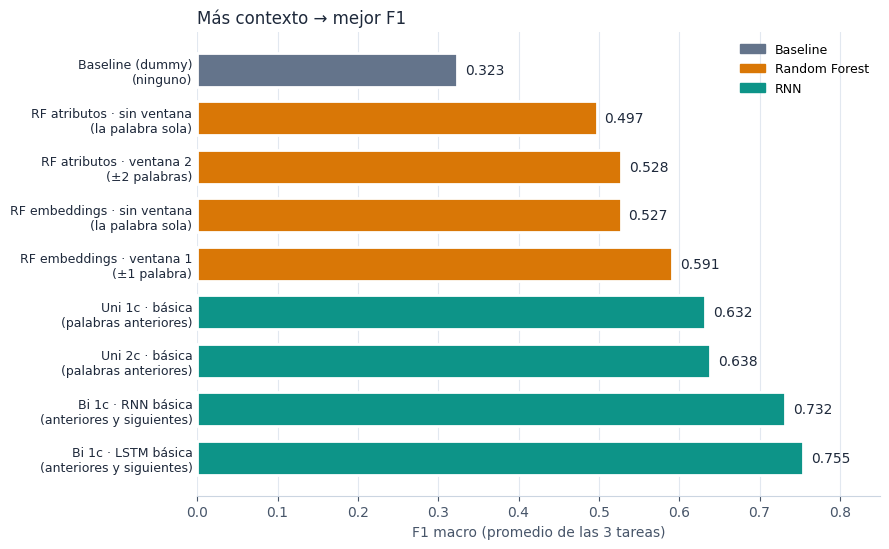

In [169]:
# F1 macro promedio según cuánto contexto ve cada modelo (de menos a más)
import os
import matplotlib.pyplot as plt
from matplotlib.patches import Patch

PROMEDIO = "Promedio de las 3 tareas"
COLORES = {"Baseline": "#64748B", "Random Forest": "#D97706", "RNN": "#0D9488"}

# (modelo, contexto que ve, familia, tabla de donde sale)
escalera = [
    ("Baseline (dummy)",            "ninguno",                 "Baseline",      resumen_finalistas),
    ("RF atributos · sin ventana",  "la palabra sola",         "Random Forest", resumen_rf),
    ("RF atributos · ventana 2",    "±2 palabras",             "Random Forest", resumen_rf),
    ("RF embeddings · sin ventana", "la palabra sola",         "Random Forest", resumen_rf),
    ("RF embeddings · ventana 1",   "±1 palabra",              "Random Forest", resumen_rf),
    ("Uni 1c · básica",             "palabras anteriores",     "RNN",           resumen_redes),
    ("Uni 2c · básica",             "palabras anteriores",     "RNN",           resumen_redes),
    ("Bi 1c · RNN básica",          "anteriores y siguientes", "RNN",           resumen_redes),
    ("Bi 1c · LSTM básica",         "anteriores y siguientes", "RNN",           resumen_redes),
]
nombres = [f"{modelo}\n({contexto})" for modelo, contexto, _, _ in escalera]
valores = [tabla.loc[PROMEDIO, modelo] for modelo, _, _, tabla in escalera]
colores = [COLORES[familia] for _, _, familia, _ in escalera]

fig, ax = plt.subplots(figsize=(9, 5.6))
y = range(len(escalera))[::-1]  # el primero arriba
ax.barh(y, valores, color=colores, height=0.7, edgecolor="white", linewidth=2)
for yi, v in zip(y, valores):
    ax.text(v + 0.01, yi, f"{v:.3f}", va="center", fontsize=10, color="#1E293B")

ax.set_yticks(list(y))
ax.set_yticklabels(nombres, fontsize=9, color="#1E293B")
ax.set_xlim(0, 0.85)
ax.set_xlabel("F1 macro (promedio de las 3 tareas)", color="#475569")
ax.set_title("Más contexto → mejor F1", loc="left", fontsize=12, color="#1E293B")
ax.grid(axis="x", color="#E2E8F0", linewidth=0.8)
ax.set_axisbelow(True)
for lado in ("top", "right", "left"):
    ax.spines[lado].set_visible(False)
ax.spines["bottom"].set_color("#CBD5E1")
ax.tick_params(axis="y", length=0)
ax.tick_params(axis="x", colors="#475569")
ax.legend(handles=[Patch(color=c, label=f) for f, c in COLORES.items()],
          loc="upper right", frameon=False, fontsize=9)
fig.tight_layout()

os.makedirs("figuras", exist_ok=True)
fig.savefig("figuras/f1_segun_contexto.pdf", bbox_inches="tight")
fig.savefig("figuras/f1_segun_contexto.png", dpi=200, bbox_inches="tight")
plt.show()

### Evaluación en control

El modelo final se evalúa **una sola vez** en el conjunto de control (`df_test_palabras`, separado al principio y nunca usado), con los umbrales de desarrollo, sin volver a ajustarlos. Es la estimación honesta de cómo le va con datos nuevos: el F1 de desarrollo es un poco optimista, porque con esos datos se eligieron el modelo y los umbrales.

In [161]:
df_control_tokens = tokenizar_palabras(df_test_palabras)
print(f"Control: {df_control_tokens['instancia_id'].nunique()} instancias, {len(df_control_tokens)} tokens")

f1_control = f1_por_palabra(predictor_final, df_control_tokens, ajustar_umbral=False)  # umbrales de desarrollo
estilo_f1(f1_control, f"{nombre_final}: F1 por clase (por palabra) en CONTROL")

Control: 30898 instancias, 911578 tokens


,Tarea,Clase,Etiqueta,F1
0,punt_final,0,Sin signo,0.972
1,punt_final,1,.,0.733
2,punt_final,2,",",0.599
3,punt_final,3,?,0.535
4,punt_final,Macro,Promedio no ponderado,0.710
5,capitalizacion,0,minúsculas,0.980
6,capitalizacion,1,Inicial mayúscula,0.826
7,capitalizacion,2,Mixta,0.186
8,capitalizacion,3,MAYÚSCULAS,0.875
9,capitalizacion,Macro,Promedio no ponderado,0.717


In [162]:
# Desarrollo (conjunto de comparación) vs. control, F1 macro por palabra
resumen_macro({
    "Desarrollo (comparación)": finalistas[nombre_final],
    "Control": f1_control,
}).style.format("{:.3f}").set_caption(f"{nombre_final}: desarrollo vs. control")

,Desarrollo (comparación),Control
Tarea,,
punt_final,0.716,0.710
capitalizacion,0.708,0.717
punt_inicial,0.839,0.831
Promedio de las 3 tareas,0.755,0.753


### Predicciones de `datos_test.csv`

Los tokens de evaluación (`instancia_id, token_id, token`, en el orden del archivo) pasan por el modelo final con sus umbrales, y las predicciones se guardan con el formato de entrega (`formato_entrega`) en `RUTA_PREDICCIONES`. Las comas quedan entre comillas en el CSV, como pide el enunciado (pandas lo hace solo).

In [163]:
RUTA_TEST = "datos_test.csv"
RUTA_PREDICCIONES = "predicciones_test.csv"

# keep_default_na=False: un token "nan" o "null" no se lee como vacío. Las columnas a predecir vienen vacías.
df_test_entrega = pd.read_csv(RUTA_TEST, keep_default_na=False)[["instancia_id", "token_id", "token"]]
print(f"{RUTA_TEST}: {df_test_entrega['instancia_id'].nunique()} instancias, {len(df_test_entrega)} tokens")

prediccion_test = predictor_final.predecir(df_test_entrega)
entrega = formato_entrega(prediccion_test)

# Mismo orden y mismos tokens que el archivo de entrada
assert (entrega[["instancia_id", "token_id", "token"]].to_numpy() == df_test_entrega.to_numpy()).all()

entrega.to_csv(RUTA_PREDICCIONES, index=False)
print("Predicciones guardadas en", RUTA_PREDICCIONES)
entrega.head(20)

datos_test.csv: 3965 instancias, 90828 tokens
Predicciones guardadas en predicciones_test.csv


,instancia_id,token_id,token,punt_inicial,punt_final,capitalización
0,0,10109,la,,,1
1,0,67763,cuestión,,,0
2,0,10196,es,,,0
3,0,10121,que,,,0
4,0,10109,la,,,0
5,0,10173,con,,,0
6,0,100371,##fusión,,,0
7,0,10196,es,,,0
8,0,52781,fácil,,,0
9,0,10104,de,,,0


In [164]:
# Algunas instancias reconstruidas, para ver que tengan sentido
for instancia_id in prediccion_test["instancia_id"].unique()[:5]:
    print(f"{instancia_id}: {texto_desde_tokens(prediccion_test, instancia_id)}")

0: La cuestión es que la confusión es fácil de aclarar.
1: En cambio, el mismo alumnado está obteniendo unos resultados por encima de la media española En lo que se refiere al castellano y si no los obtuviera, no se preocupe, porque tomaríamos las oportunas medidas para que eso fuese así.
2: No nos extraña lo conocemos perfectamente.
3: Y en el mes de abril, hay una orden un mandato de este Parlamento exactamente para lo mismo aprobado sin ningún voto en contra, Señorías.
4: No olviden para acabar todos los que componen esta cámara que, cuando pocos de aquí muy pocos hace años confiaban en que la ley y la policía acabarían con los comandos. Nosotros sí, lo creíamos.
